# HAR-MMAct — Final Project Presentation

**Repository:** [CHENNAMSETTYVIKRAM/HAR-MMAct](https://github.com/CHENNAMSETTYVIKRAM/HAR-MMAct)

This notebook clones the public project repository, then displays the tracked experiment graphs and canonical benchmark results. It does **not** retrain models.

**Evaluation protocol:** custom subject-independent split — train subjects 1–14, validation subjects 15–17, test subjects 18–20. This is not the official MMAct competition split.

## 1. Project overview

The project combines video and wearable inertial sensor inputs for human activity recognition. The ten documented project classes are crouching, jumping, kicking, pointing, running, sitting, standing, using_phone, walking, and waving_hand.

The README identifies the primary multimodal architecture as MobileNetV2 for video and InceptionTime for sensor data, with late fusion. Sensor input comprises nine channels: phone accelerometer (3), watch accelerometer (3), and gyroscope (3). Orientation is present in the raw dataset but excluded from the nine-channel model input.

See the repository's `docs/LABEL_MAPPING.md` and `docs/DATASET_AUDIT.md` for label and data evidence. Exact synchronization details should be described from the implementation rather than inferred from the plotted outputs.

## 2. Dataset and preprocessing

The project README documents the paired MMAct video/sensor sample inventory and custom subject partition. The two Kaggle input datasets are:

- `vikramche/trimmed-scene-video`
- `vikramche/mmact-trimmed`

This presentation notebook only needs the repository's saved outputs. It does not need to download the raw MMAct media to render the graphs.

## 3. Model architectures

Tracked experiments include Custom CNN, MobileNetV2, sensor-only InceptionTime, sensor-only TCN, multimodal late fusion, and gated multimodal TCN.

The primary multimodal experiment is MobileNetV2 + InceptionTime late fusion. The complete architecture descriptions are in the repository README.

In [6]:
from pathlib import Path
import subprocess, sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

REPO_URL = "https://github.com/CHENNAMSETTYVIKRAM/HAR-MMAct.git"
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
REPO = WORK / "HAR-MMAct"

if not (REPO / "outputs").is_dir():
    if REPO.exists():
        print("Removing incomplete repository folder:", REPO)
        import shutil
        shutil.rmtree(REPO)
    result = subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO)],
        text=True, capture_output=True
    )
    if result.returncode != 0:
        raise RuntimeError("Git clone failed:\n" + result.stderr)

OUTPUTS = REPO / "outputs"
print("Repository ready:", REPO)
print("Tracked outputs:", OUTPUTS)

plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})

def show_image(rel, title=None):
    path = REPO / rel
    if not path.is_file():
        print("MISSING:", rel)
        return False
    if title:
        display(Markdown("### " + title))
    print(rel)
    display(Image(filename=str(path)))
    return True

def show_many(title, paths):
    display(Markdown("### " + title))
    shown = 0
    for rel in paths:
        shown += int(show_image(rel))
    print(f"Displayed {shown}/{len(paths)} available images.")

Repository ready: /kaggle/working/HAR-MMAct
Tracked outputs: /kaggle/working/HAR-MMAct/outputs


## 4. Training results — epoch-wise accuracy and loss

These are the saved training/validation curves. They do not represent epoch-wise test-set evaluation.

### Primary Multimodal — Training vs Validation Accuracy

outputs/exp1_multimodal/plots/train_vs_val_accuracy.png


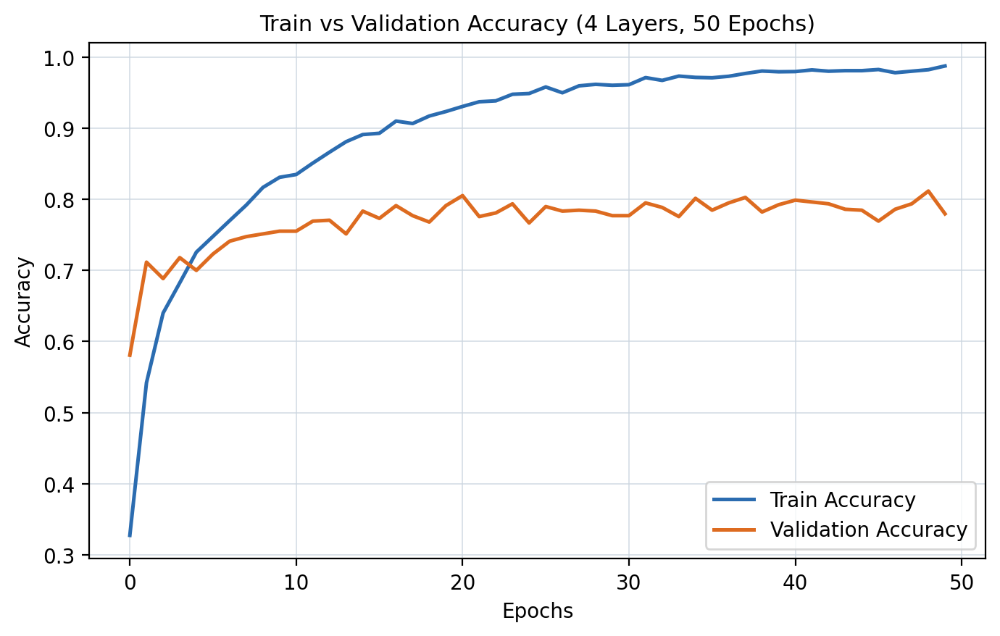

### Primary Multimodal — Training vs Validation Loss

outputs/exp1_multimodal/plots/train_vs_val_loss.png


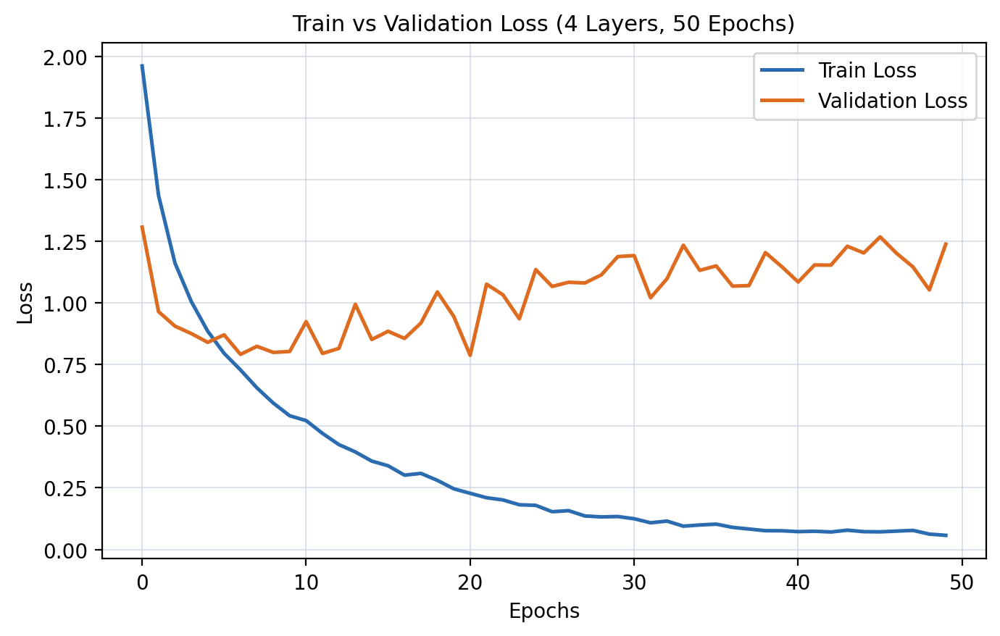

### All Nine Models — Training vs Validation Accuracy

outputs/final_test/all_models/all_nine_training_validation_accuracy.png


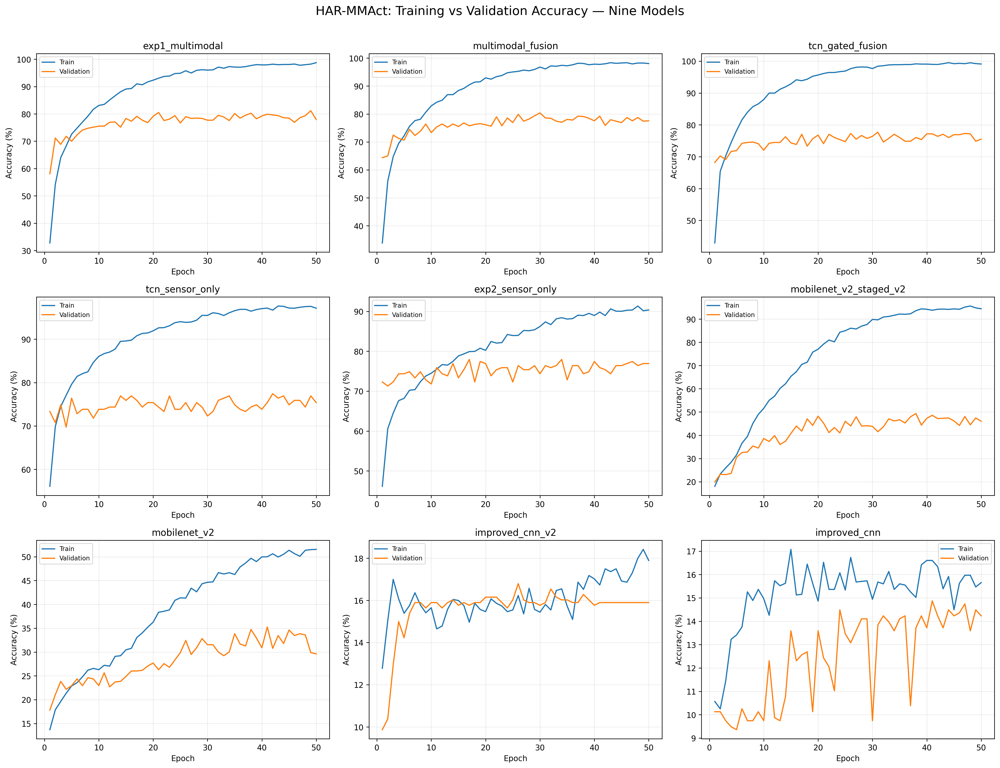

### All Nine Models — Training vs Validation Loss

outputs/final_test/all_models/all_nine_training_validation_loss.png


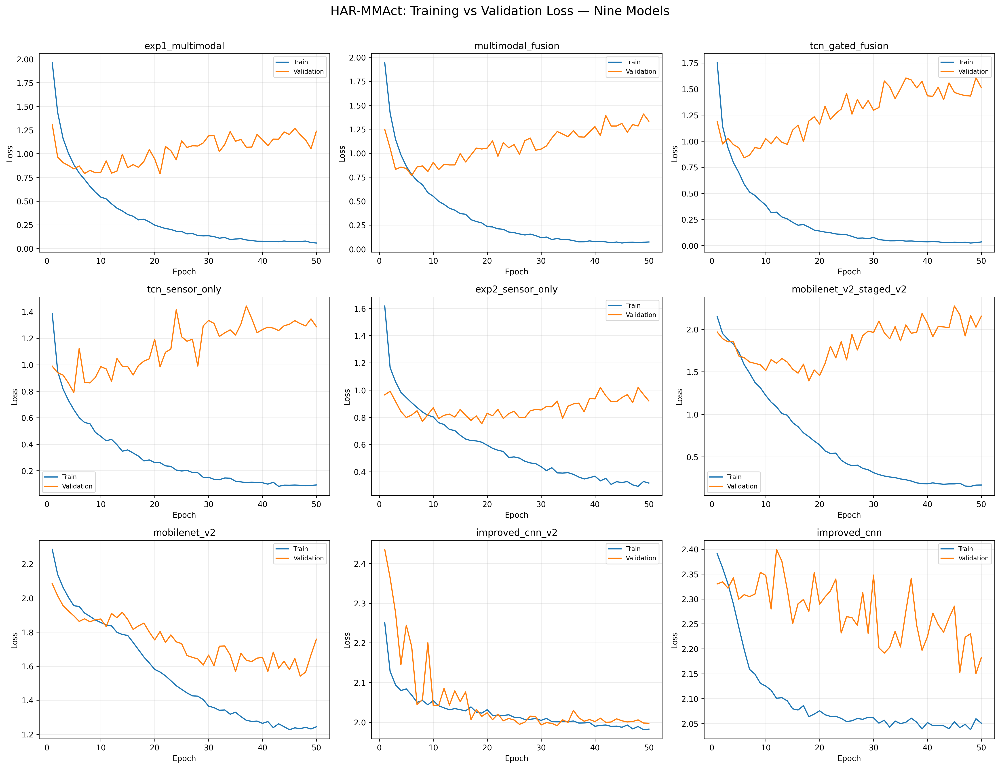

### Primary Multimodal — Training and Final Test Accuracy

outputs/exp1_multimodal/final_training_test_plots/training_vs_test_accuracy.png


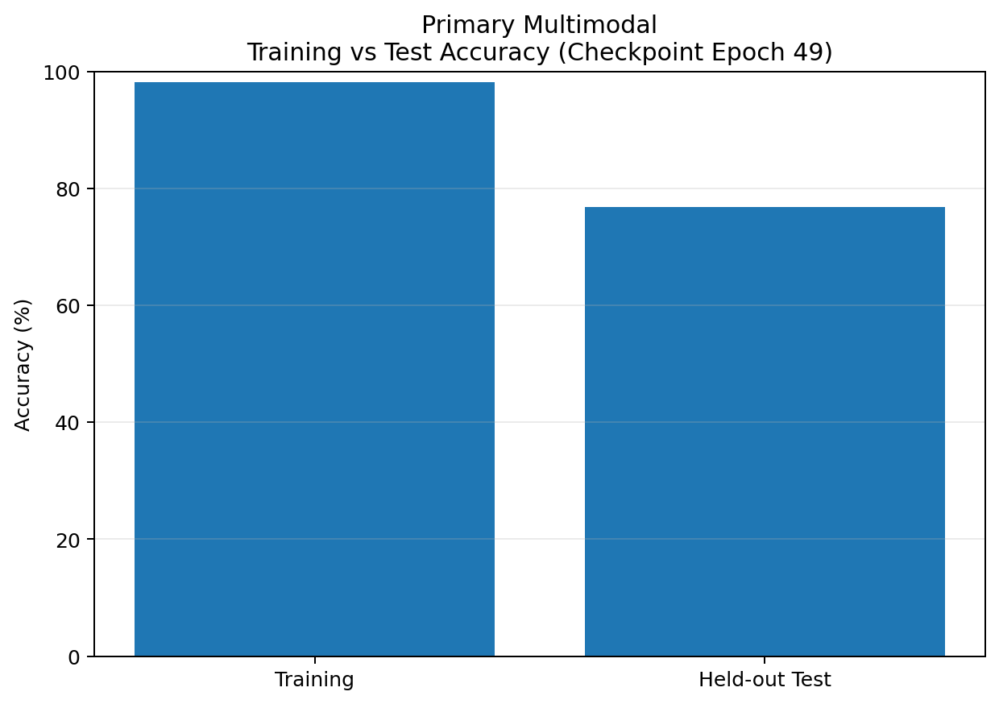

True

In [7]:
# Primary multimodal learning curves
show_image("outputs/exp1_multimodal/plots/train_vs_val_accuracy.png",
           "Primary Multimodal — Training vs Validation Accuracy")
show_image("outputs/exp1_multimodal/plots/train_vs_val_loss.png",
           "Primary Multimodal — Training vs Validation Loss")

# Consolidated 9-model epoch-wise histories
show_image("outputs/final_test/all_models/all_nine_training_validation_accuracy.png",
           "All Nine Models — Training vs Validation Accuracy")
show_image("outputs/final_test/all_models/all_nine_training_validation_loss.png",
           "All Nine Models — Training vs Validation Loss")

# Primary model training against final test accuracy (not per-epoch test loss)
show_image("outputs/exp1_multimodal/final_training_test_plots/training_vs_test_accuracy.png",
           "Primary Multimodal — Training and Final Test Accuracy")

## 5. Hyperparameter tuning

The tracked tuning artifacts below show the saved trial comparison and tuning history. Trial-level validation results are tuning evidence; they are not extra held-out test results.

### Hyperparameter Tuning Comparison

outputs/final_test/all_models/hyperparameter_tuning_comparison.png


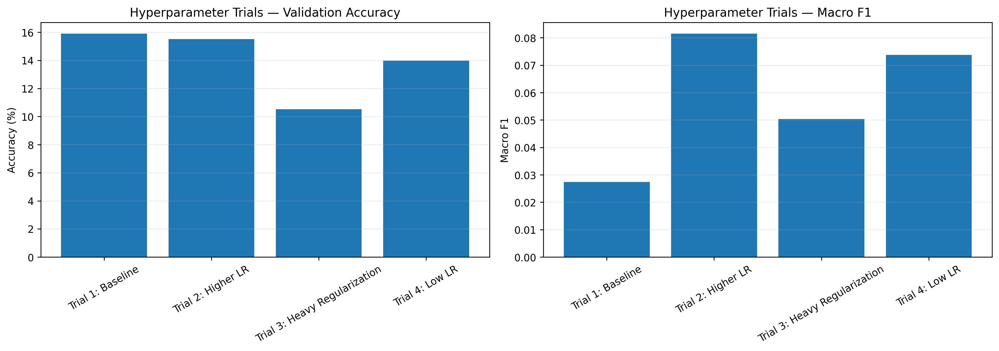

### Additional Video Experiment — Hyperparameter Trials

outputs/video_improvement_runs/20261116_091302/hyperparameter_visual_comparison.png


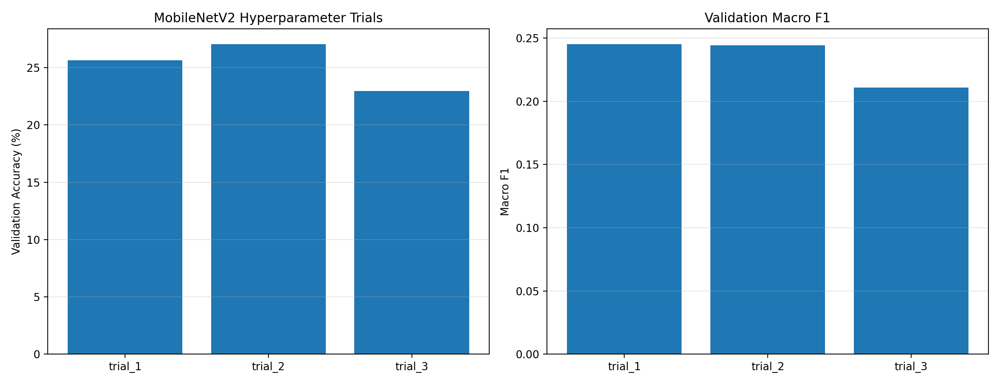

Tuning table: outputs/final_test/all_models/hyperparameter_tuning_results.csv


,Trial,Validation Accuracy,Macro F1
0,Trial 1: Baseline,15.90,0.0274
1,Trial 2: Higher LR,15.51,0.0815
2,Trial 3: Heavy Regularization,10.51,0.0504
3,Trial 4: Low LR,13.97,0.0737


In [8]:
show_image("outputs/final_test/all_models/hyperparameter_tuning_comparison.png",
           "Hyperparameter Tuning Comparison")
show_image("outputs/video_improvement_runs/20261116_091302/hyperparameter_visual_comparison.png",
           "Additional Video Experiment — Hyperparameter Trials")

# Display the saved trial table if present.
trial_csv = OUTPUTS / "final_test/all_models/hyperparameter_tuning_results.csv"
if not trial_csv.exists():
    trial_csv = OUTPUTS / "video_improvement_runs/20261116_091302/hyperparameter_trials.csv"

if trial_csv.exists():
    print("Tuning table:", trial_csv.relative_to(REPO))
    display(pd.read_csv(trial_csv))
else:
    print("No tracked hyperparameter trial CSV found.")

## 6. Transfer learning — MobileNetV2

The MobileNetV2 curves below are the saved experiment histories. Validation plots remain validation diagnostics.

### MobileNetV2 — Training vs Validation Accuracy

outputs/mobilenet_v2/plots/train_vs_val_accuracy.png


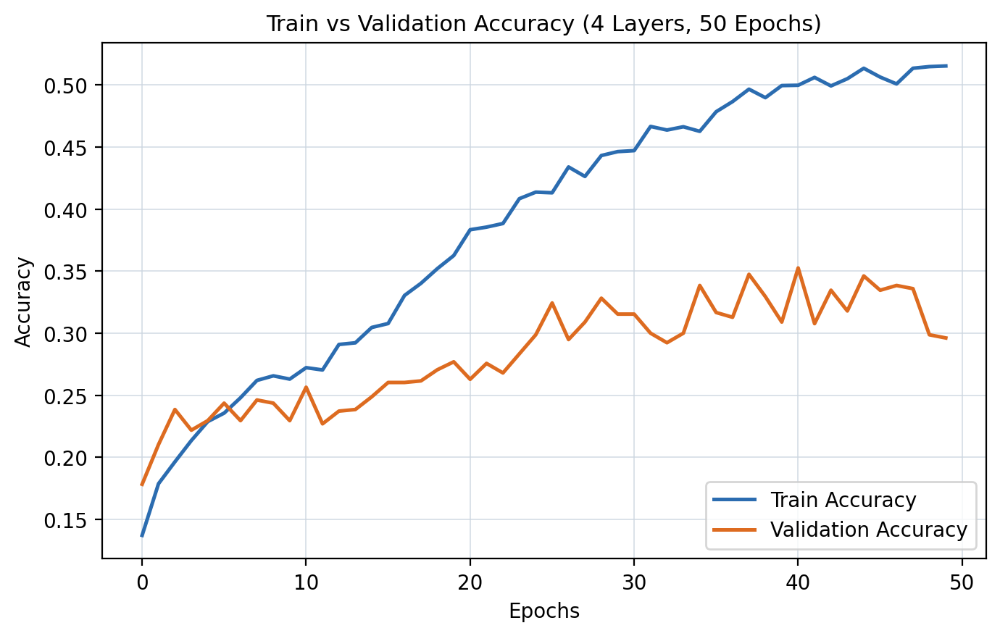

### MobileNetV2 — Training vs Validation Loss

outputs/mobilenet_v2/plots/train_vs_val_loss.png


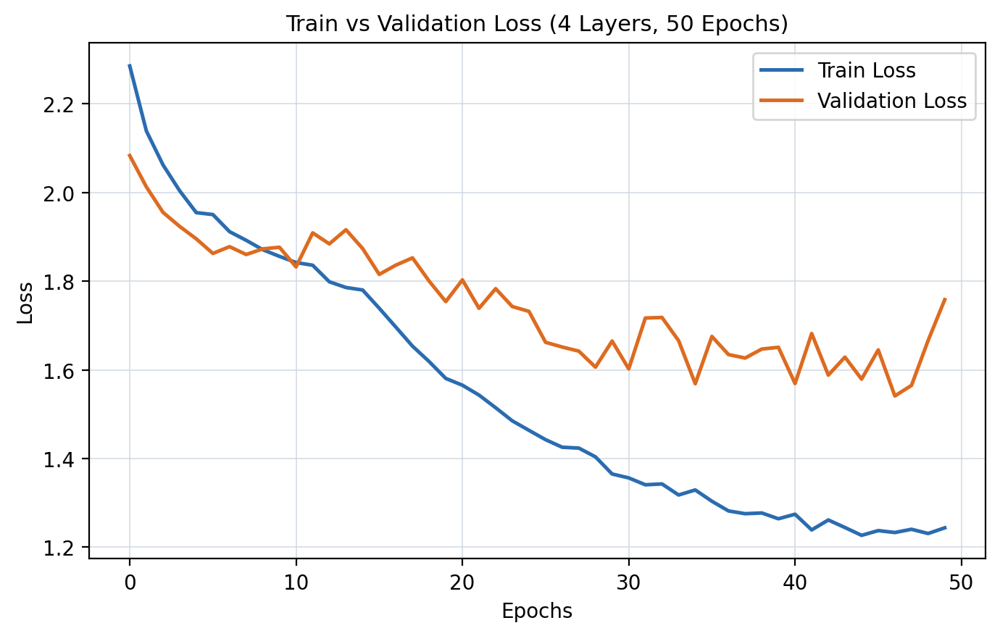

### MobileNetV2 — Saved Training/Validation Accuracy

outputs/mobilenet_v2/final_training_test_plots/training_validation_accuracy.png


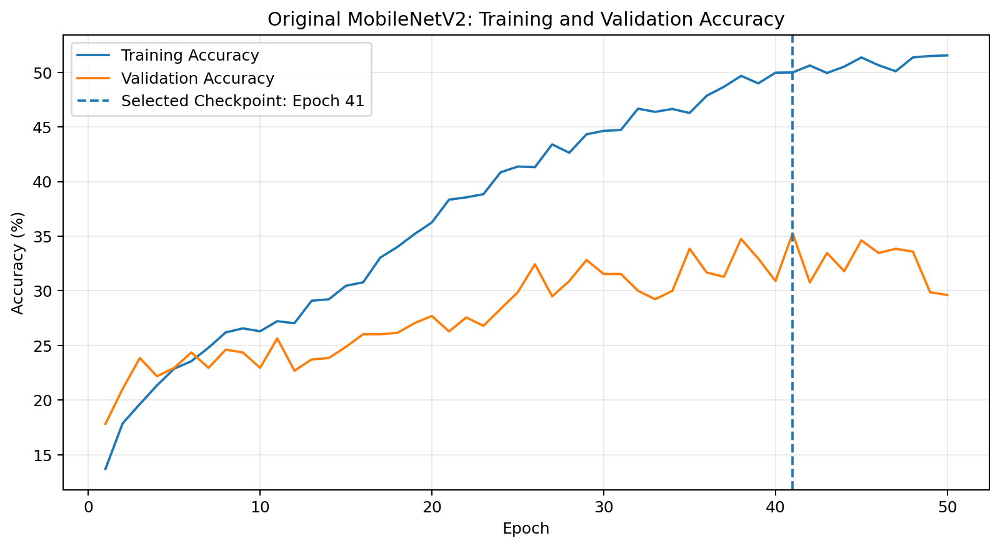

### MobileNetV2 — Saved Training/Validation Loss

outputs/mobilenet_v2/final_training_test_plots/training_validation_loss.png


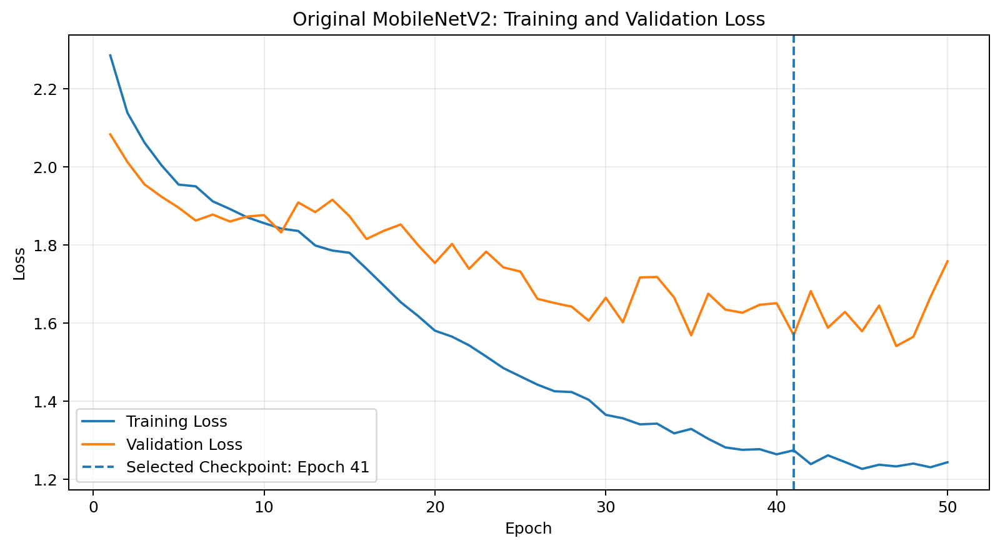

True

In [9]:
show_image("outputs/mobilenet_v2/plots/train_vs_val_accuracy.png",
           "MobileNetV2 — Training vs Validation Accuracy")
show_image("outputs/mobilenet_v2/plots/train_vs_val_loss.png",
           "MobileNetV2 — Training vs Validation Loss")
show_image("outputs/mobilenet_v2/final_training_test_plots/training_validation_accuracy.png",
           "MobileNetV2 — Saved Training/Validation Accuracy")
show_image("outputs/mobilenet_v2/final_training_test_plots/training_validation_loss.png",
           "MobileNetV2 — Saved Training/Validation Loss")

## 7. Final evaluation — confusion matrix, precision, recall, F1, ROC and PR

The primary multimodal held-out test plots are shown first. Test plots for other benchmark models are included where tracked. Validation diagnostic plots are explicitly labeled as validation.

### Primary Multimodal — Held-out Test Evaluation

outputs/exp1_multimodal/final_test_plots/test_confusion_matrix.png


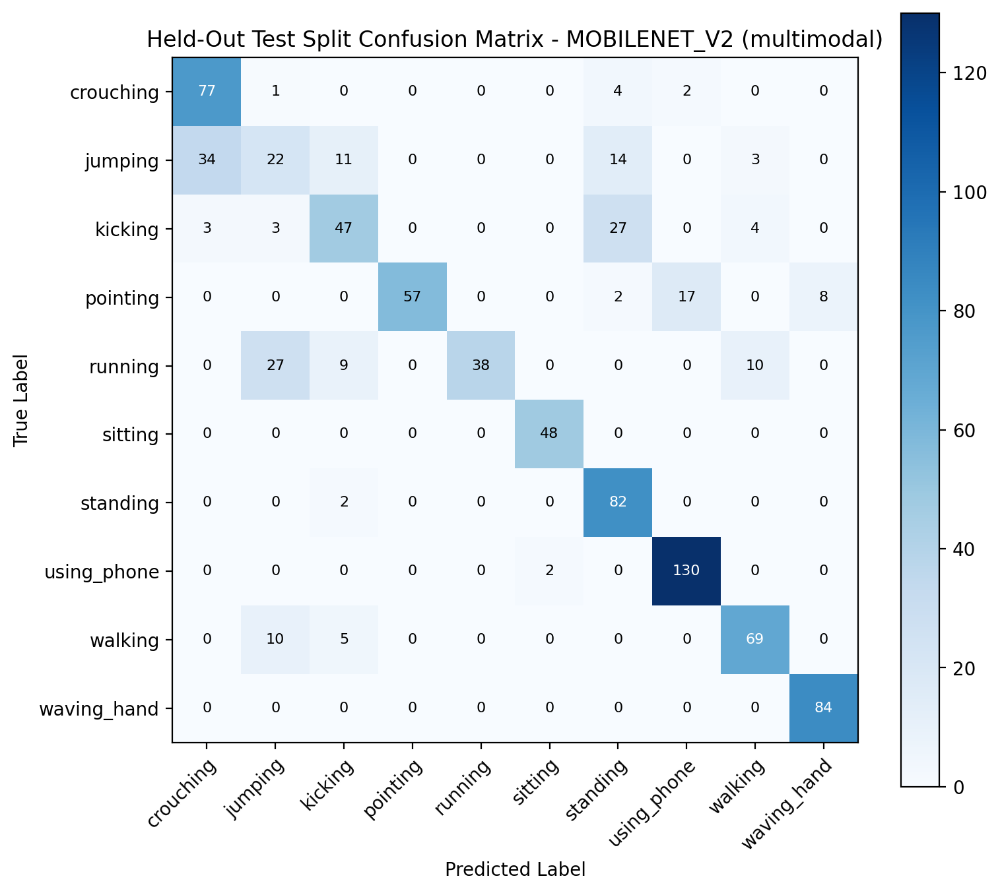

outputs/exp1_multimodal/final_test_plots/test_precision_bars_mobilenet_v2.png


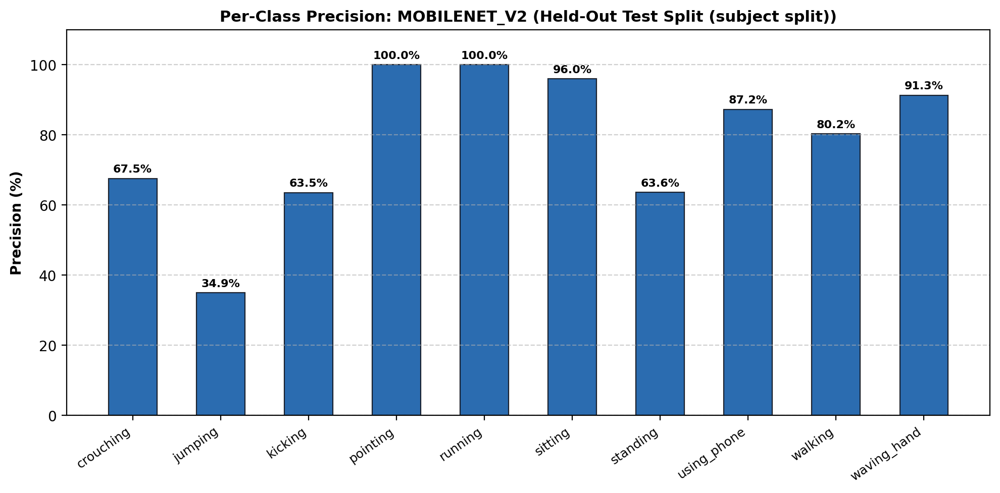

outputs/exp1_multimodal/final_test_plots/test_recall_bars_mobilenet_v2.png


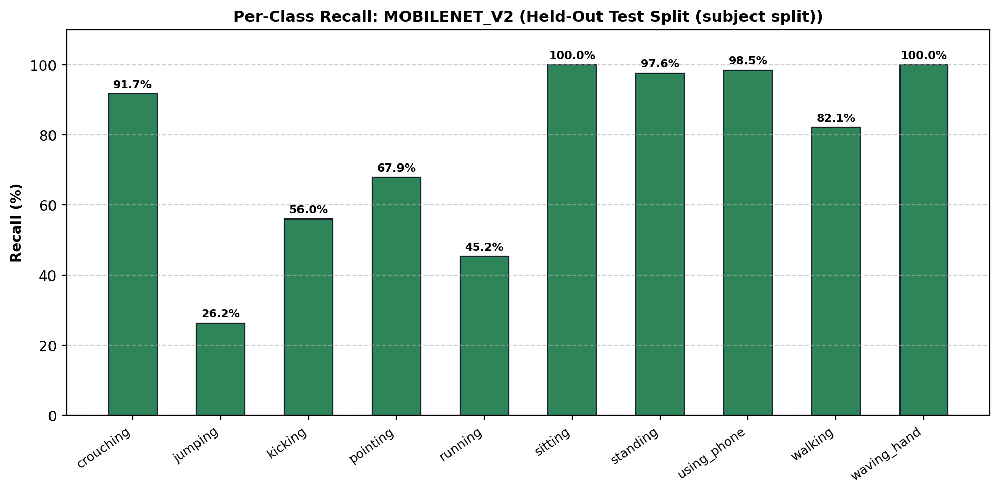

outputs/exp1_multimodal/final_test_plots/test_f1_bars_mobilenet_v2.png


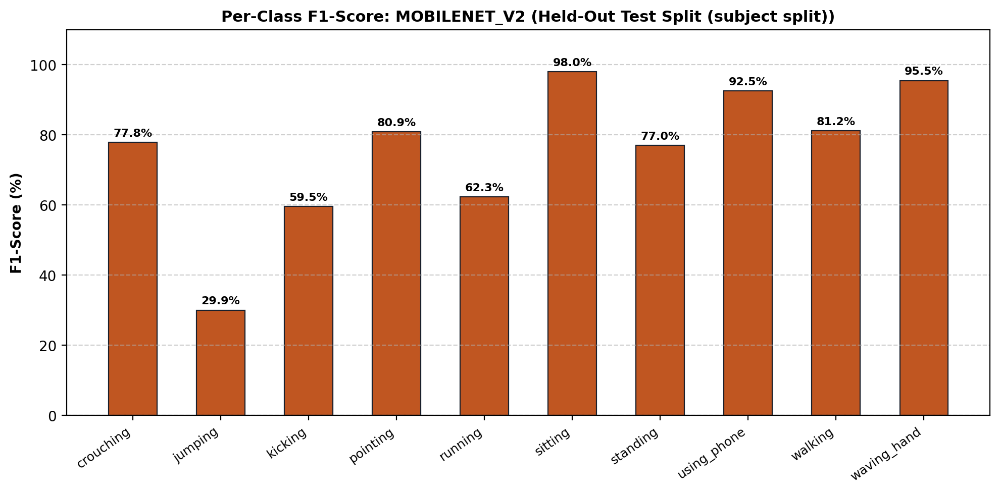

outputs/exp1_multimodal/final_test_plots/test_roc_ovr.png


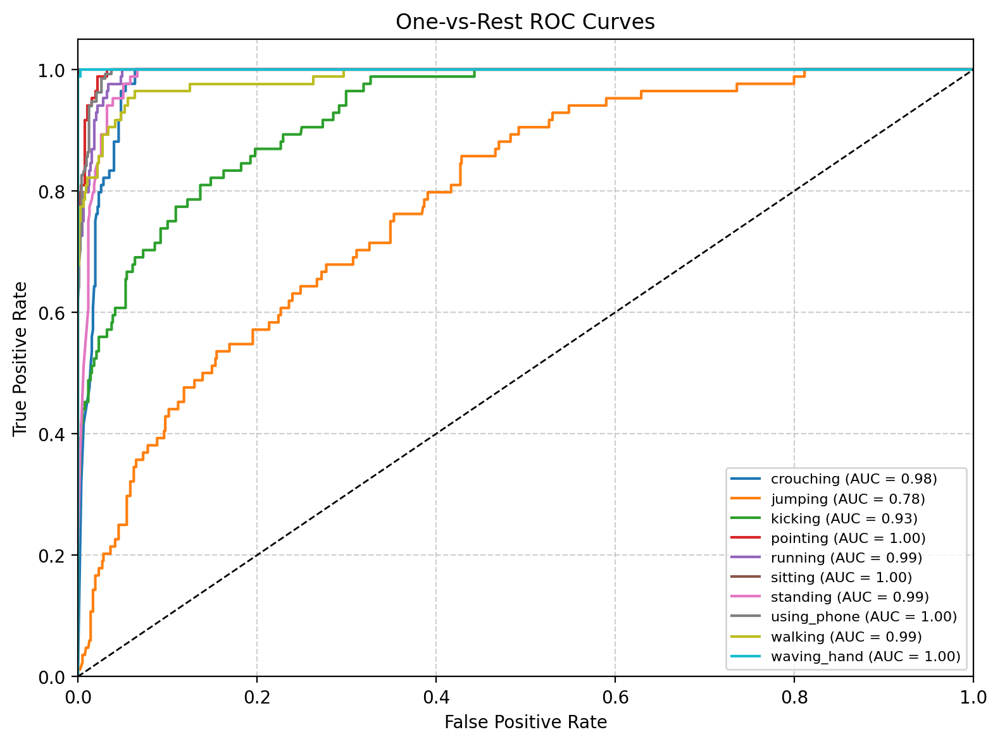

outputs/exp1_multimodal/final_test_plots/test_pr_curves.png


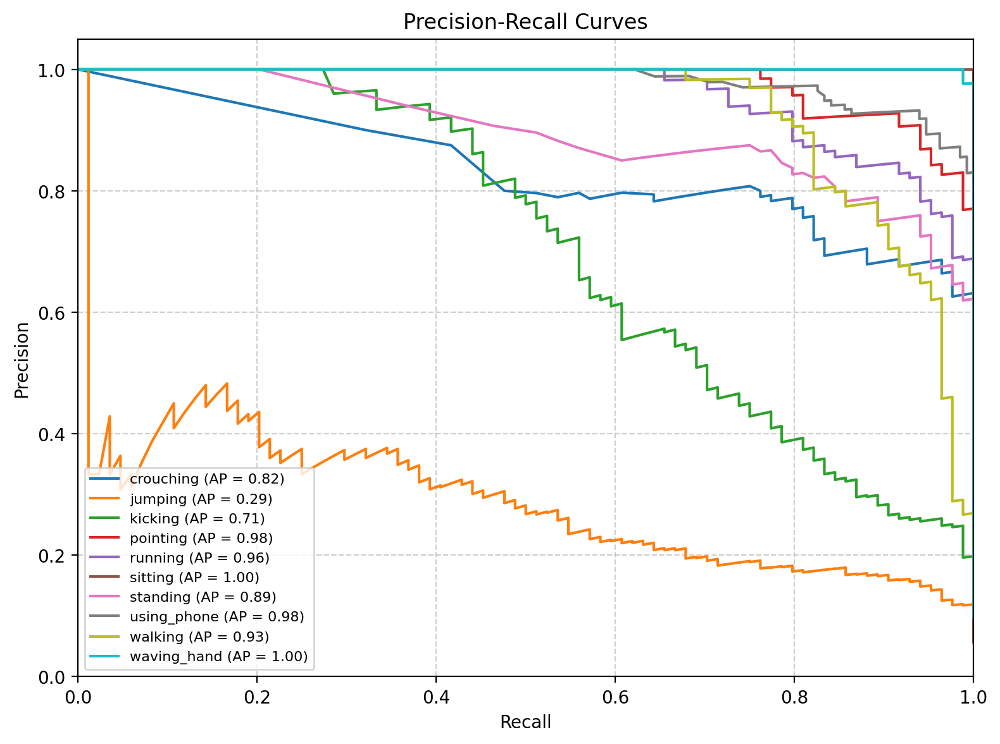

Displayed 6/6 available images.


### Custom CNN — Held-out Test Evaluation

outputs/improved_cnn/final_test_plots/test_confusion_matrix.png


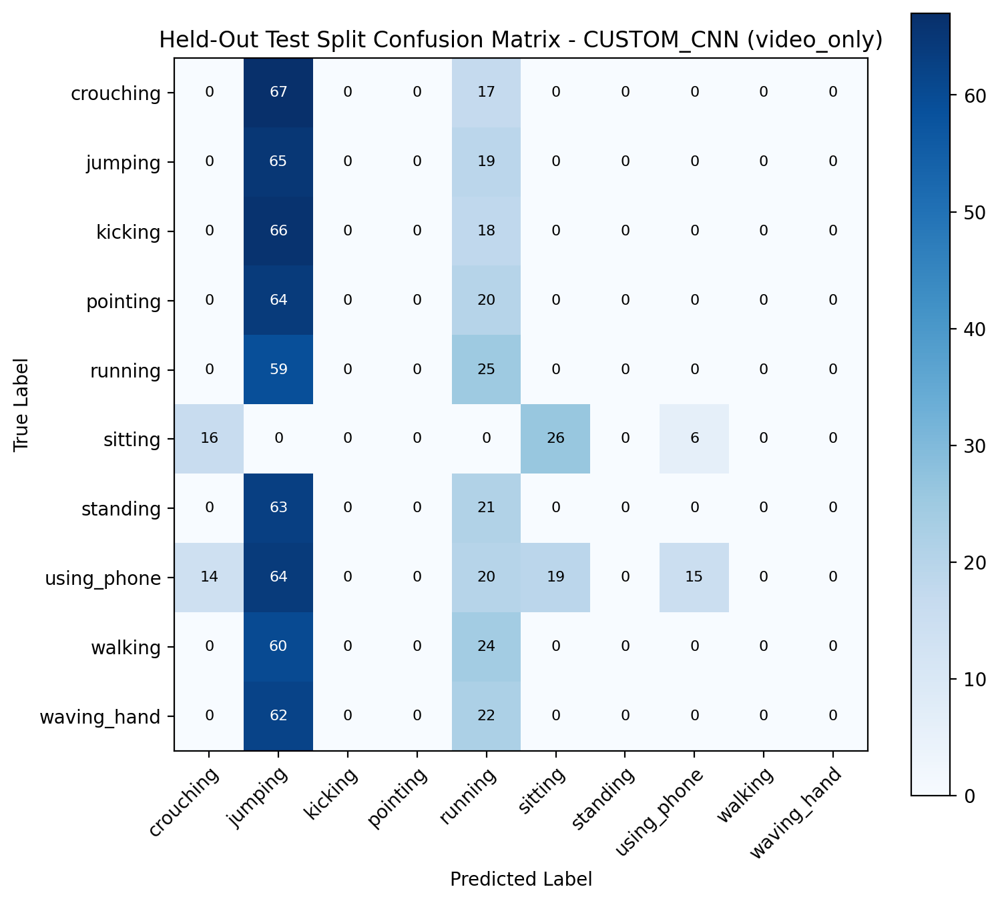

outputs/improved_cnn/final_test_plots/test_precision_bars_custom_cnn.png


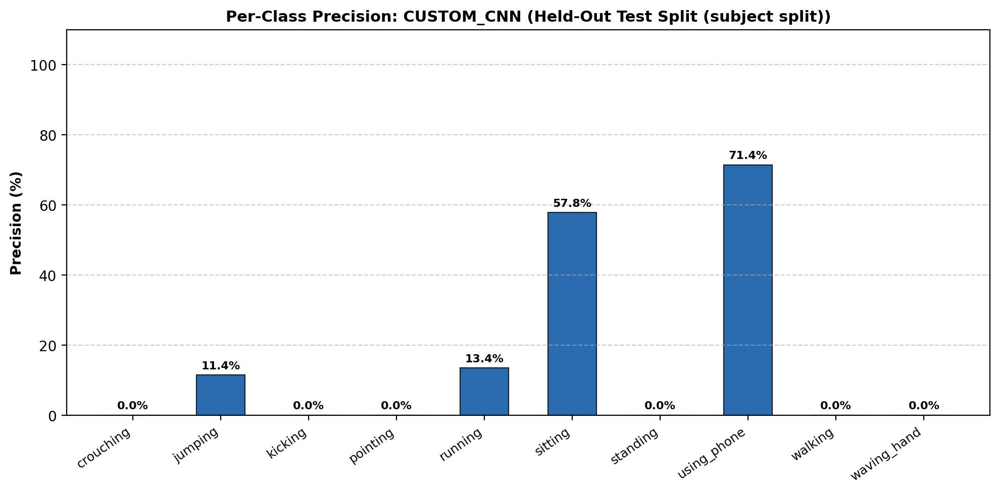

outputs/improved_cnn/final_test_plots/test_recall_bars_custom_cnn.png


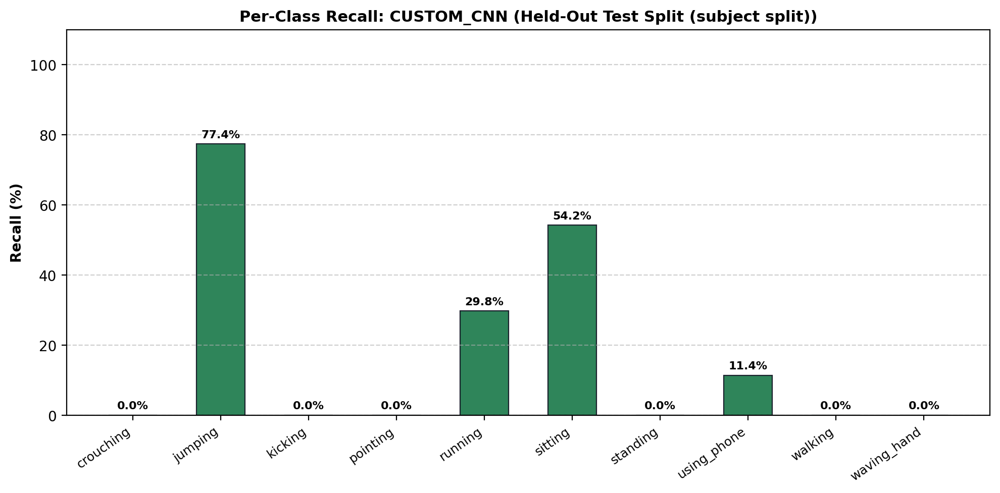

outputs/improved_cnn/final_test_plots/test_f1_bars_custom_cnn.png


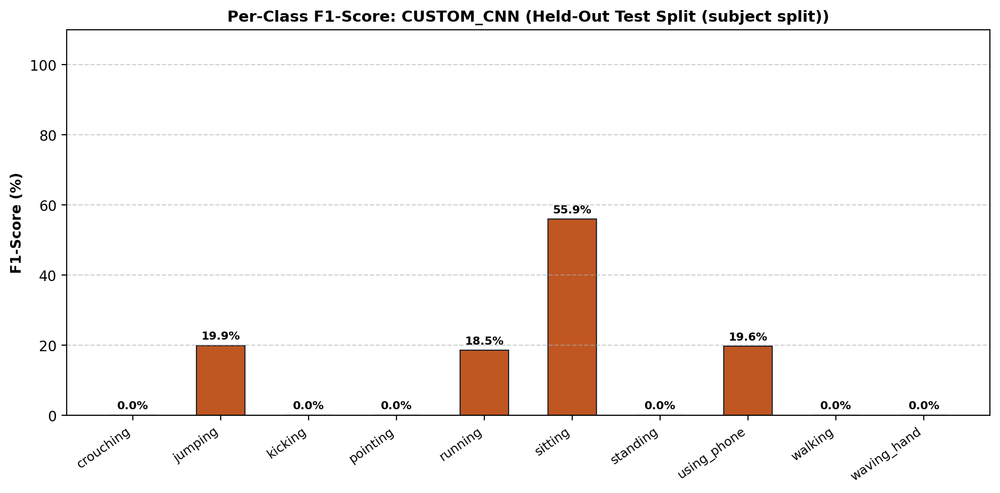

outputs/improved_cnn/final_test_plots/test_roc_ovr.png


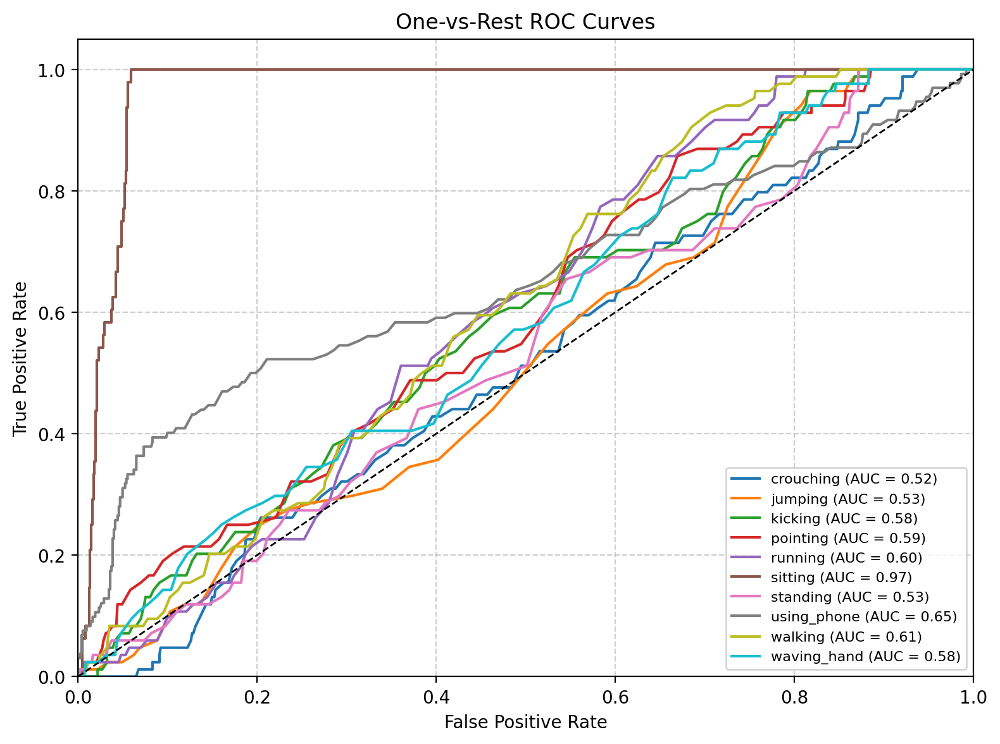

outputs/improved_cnn/final_test_plots/test_pr_curves.png


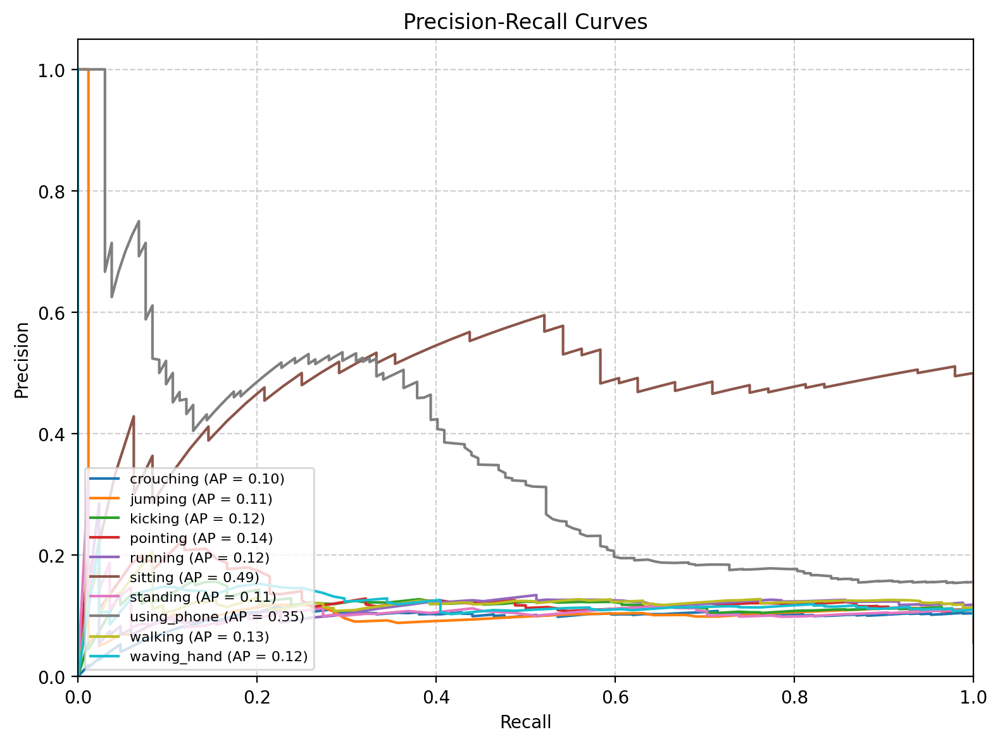

Displayed 6/6 available images.


### MobileNetV2 — Held-out Test Evaluation

outputs/mobilenet_v2/final_test_plots/test_confusion_matrix.png


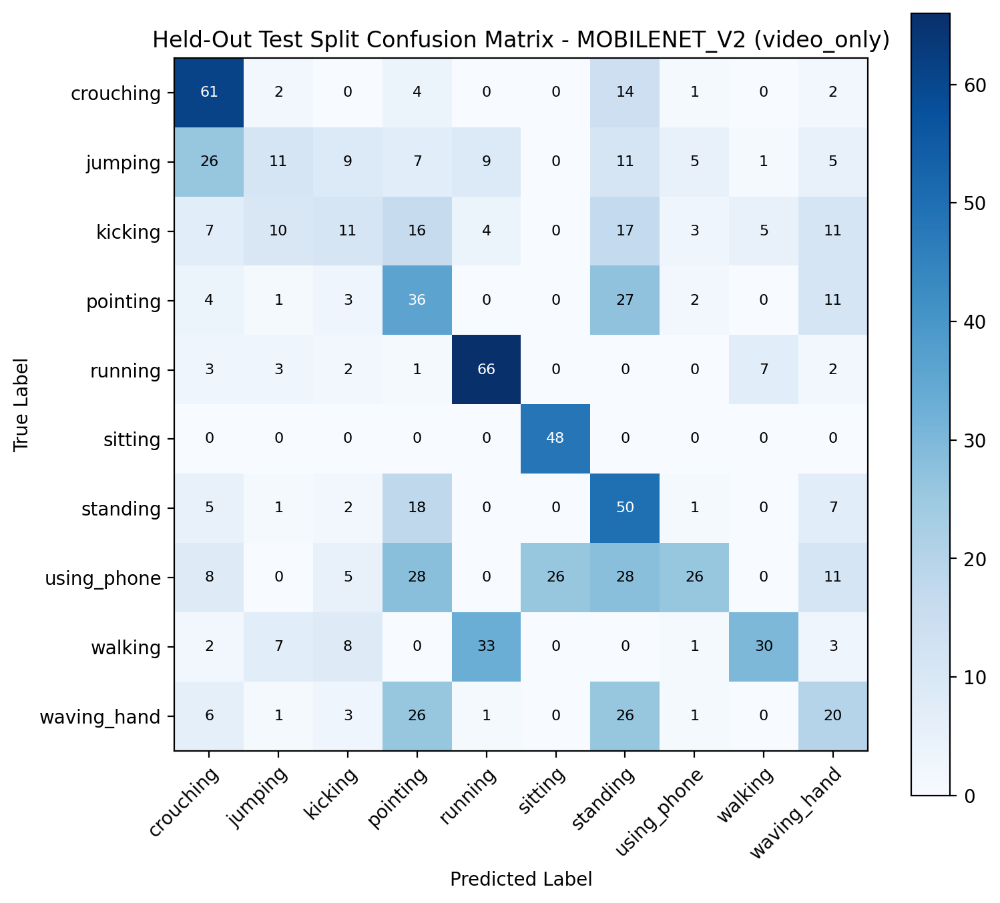

outputs/mobilenet_v2/final_test_plots/test_precision_bars_mobilenet_v2.png


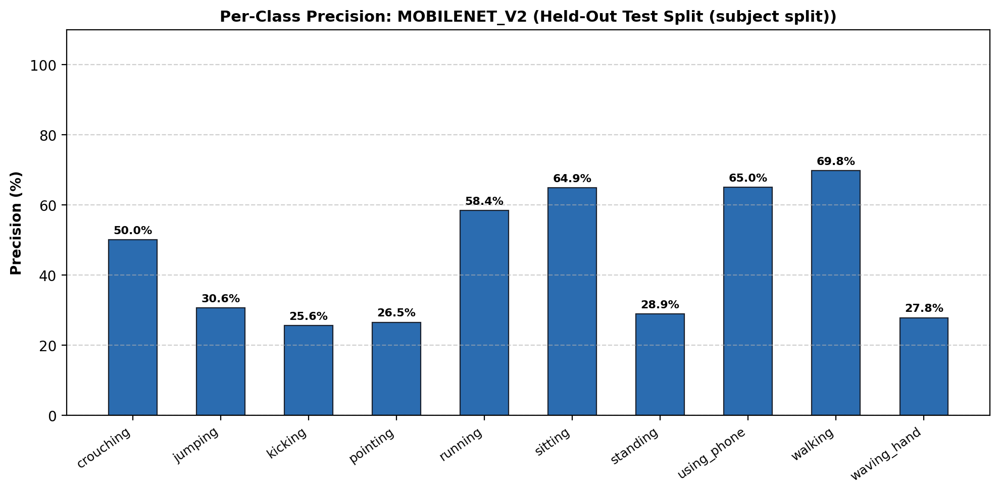

outputs/mobilenet_v2/final_test_plots/test_recall_bars_mobilenet_v2.png


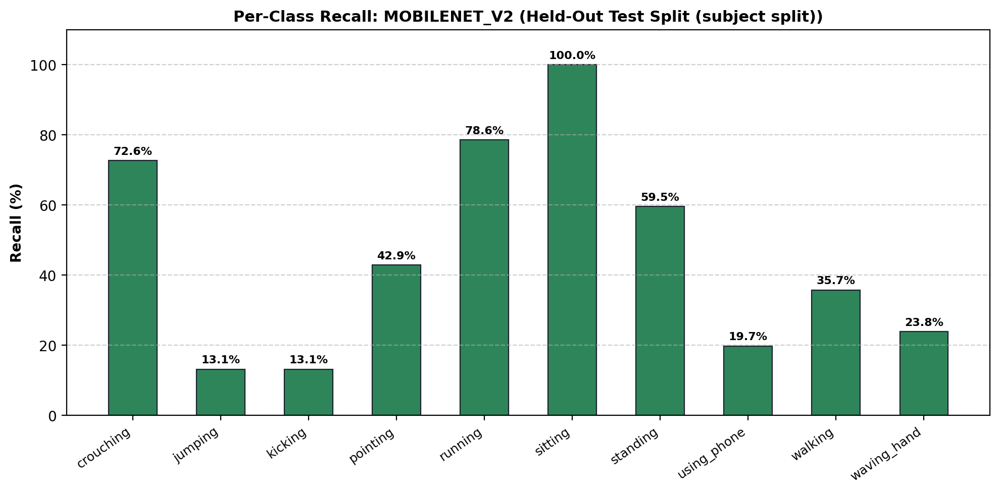

outputs/mobilenet_v2/final_test_plots/test_f1_bars_mobilenet_v2.png


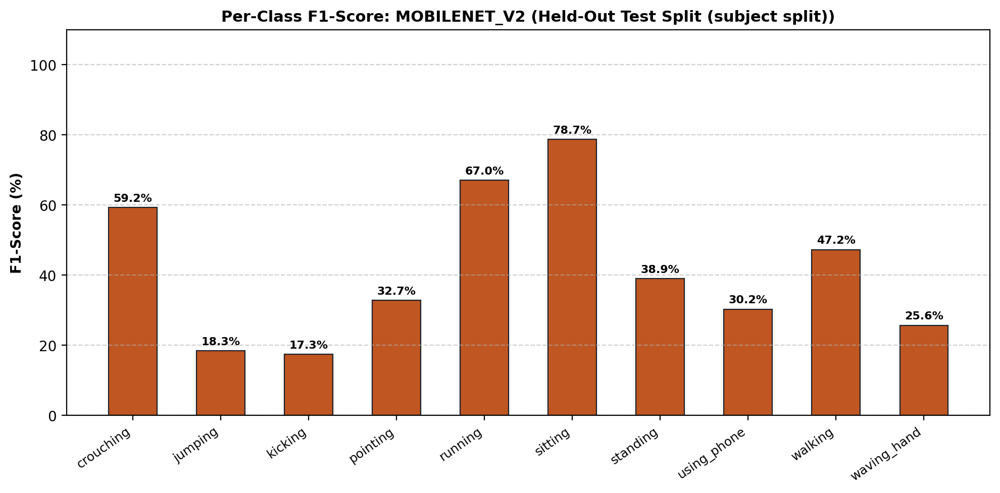

outputs/mobilenet_v2/final_test_plots/test_roc_ovr.png


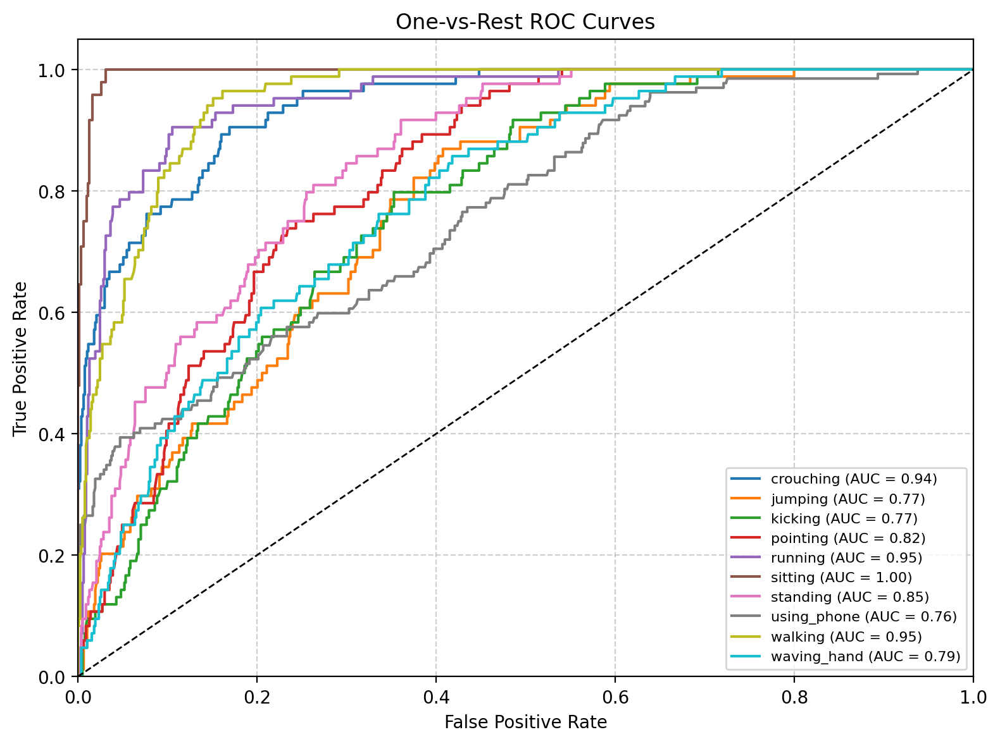

outputs/mobilenet_v2/final_test_plots/test_pr_curves.png


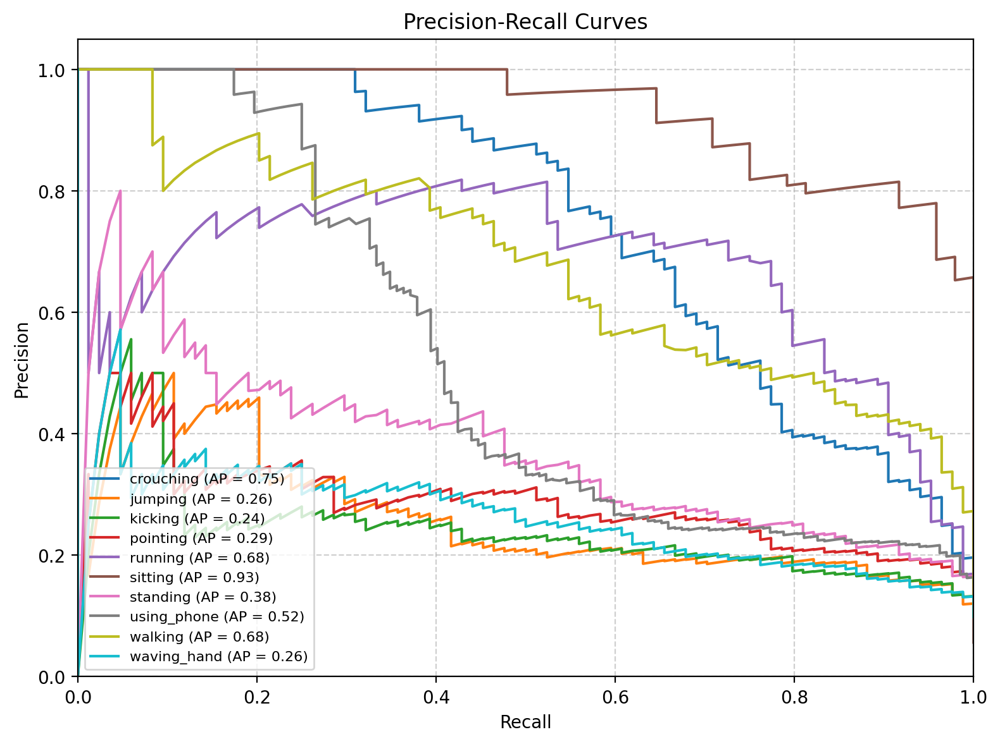

Displayed 6/6 available images.


### Sensor-only InceptionTime — Held-out Test Evaluation

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_confusion_matrix.png


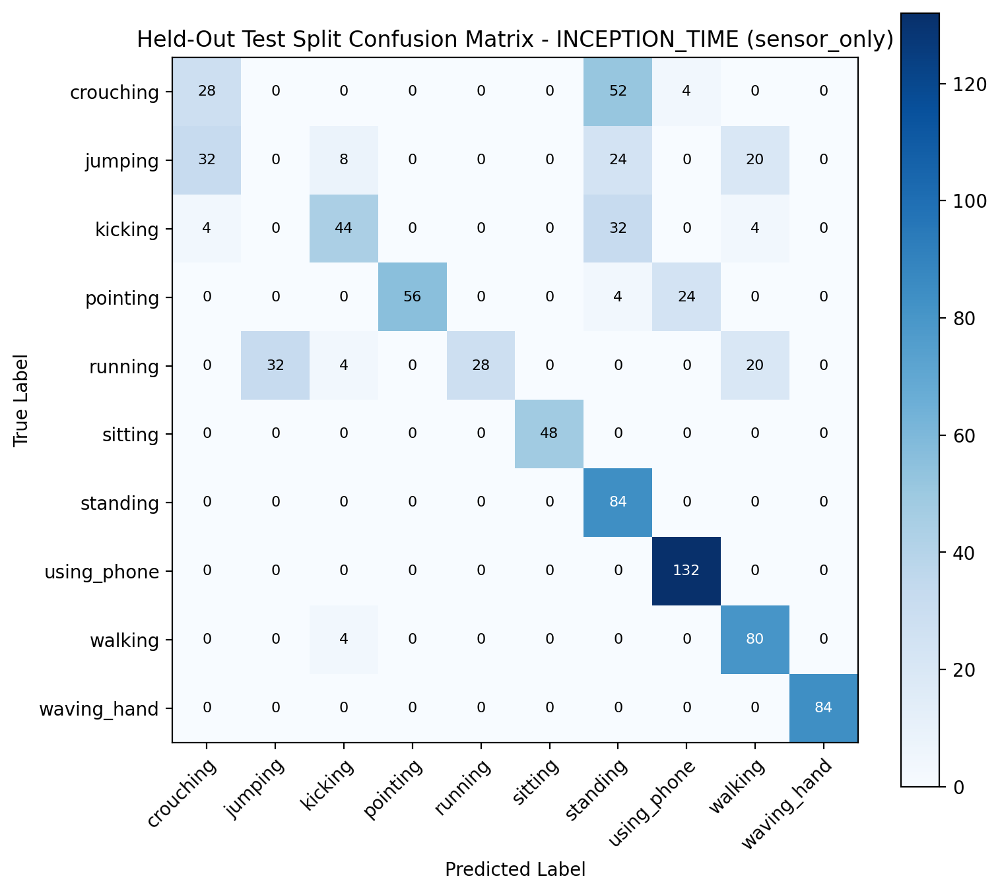

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_precision_bars_inception_time.png


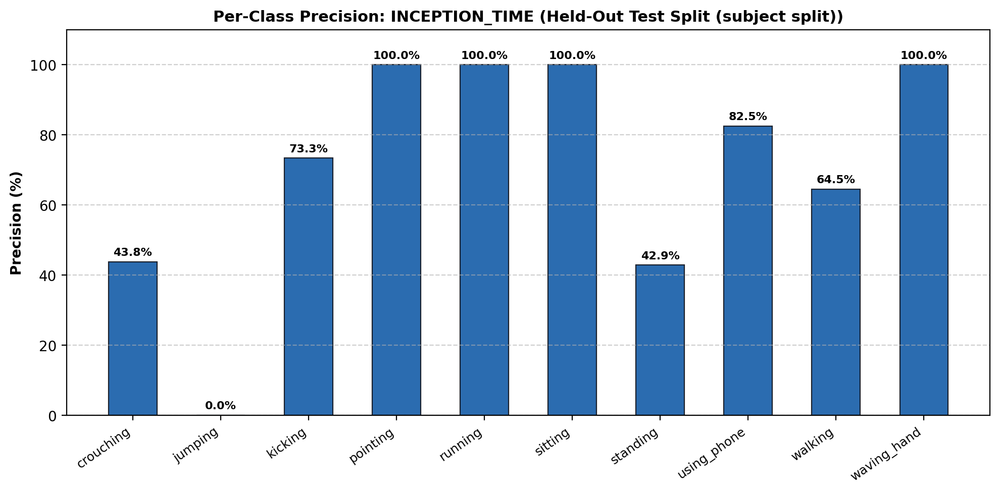

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_recall_bars_inception_time.png


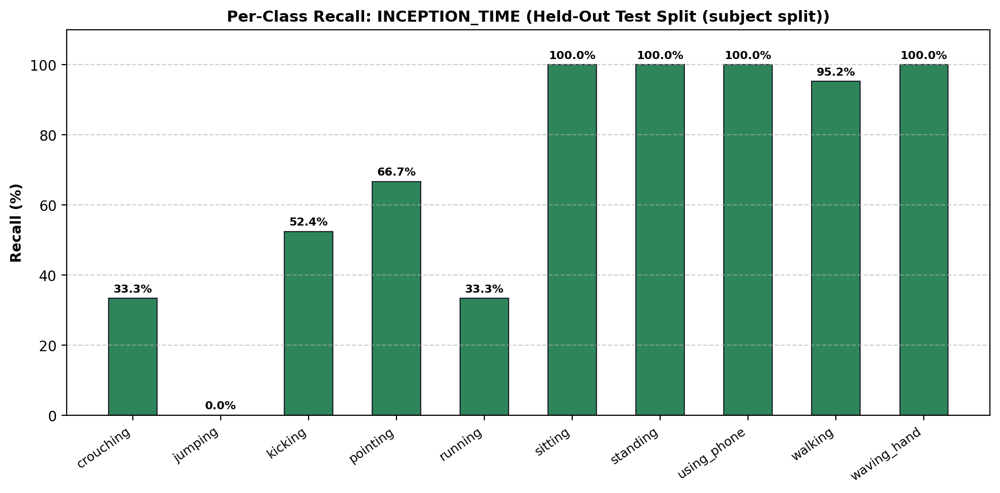

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_f1_bars_inception_time.png


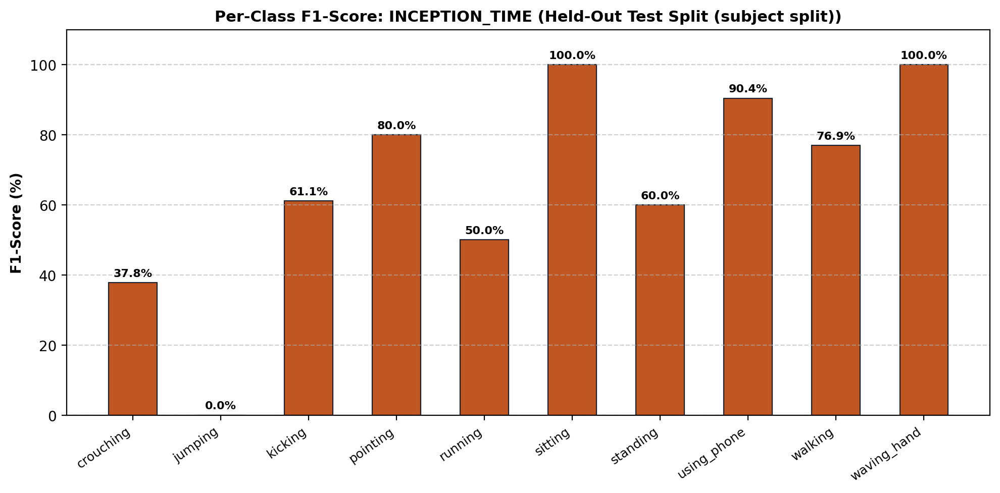

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_roc_ovr.png


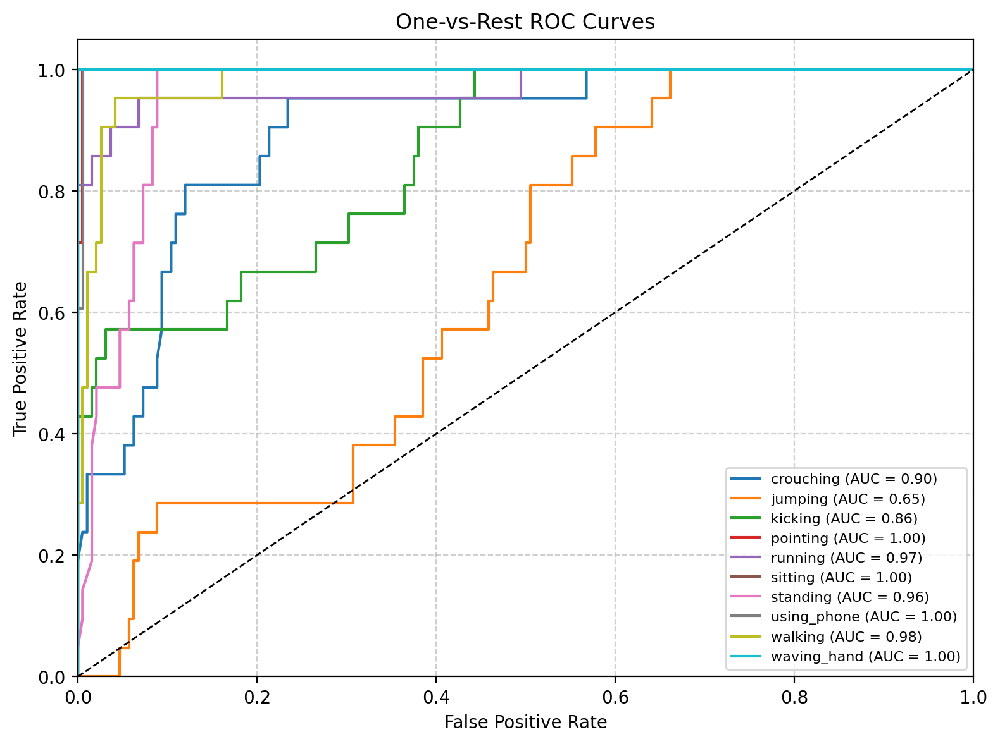

outputs/sensor_only_inception_time_v2_retrained/final_test_plots/test_pr_curves.png


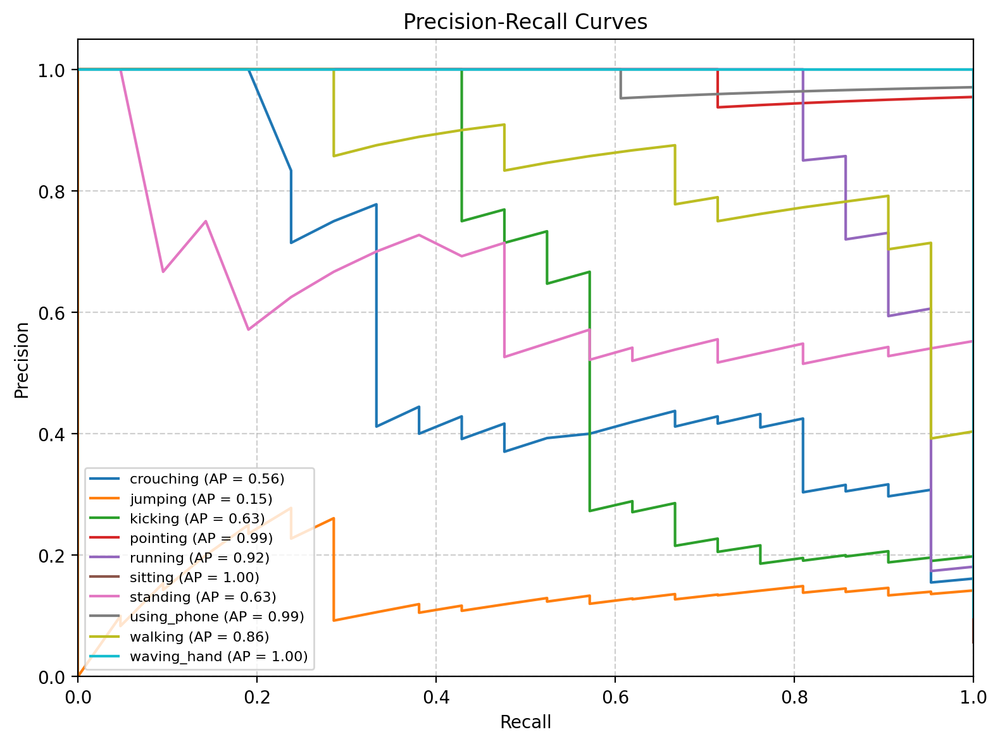

Displayed 6/6 available images.


### Sensor-only TCN — Held-out Test Evaluation

outputs/final_test/all_models/tcn_sensor_only_plots/test_confusion_matrix.png


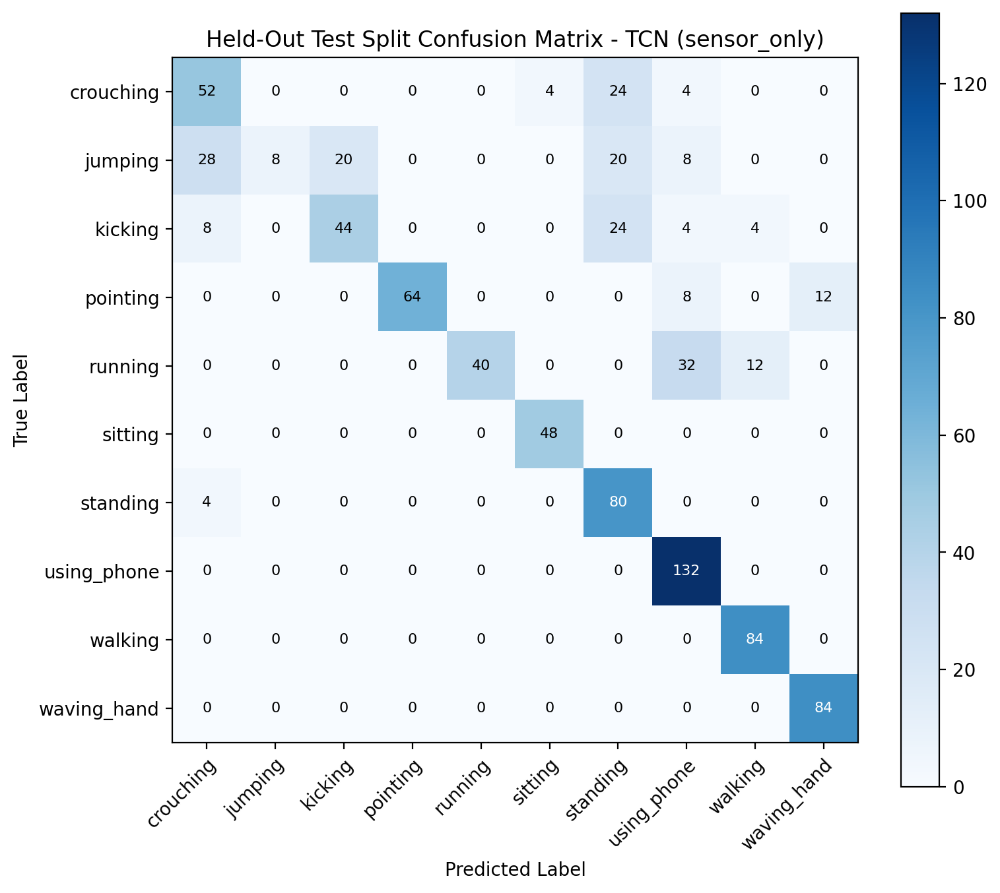

outputs/final_test/all_models/tcn_sensor_only_plots/test_precision_bars_tcn.png


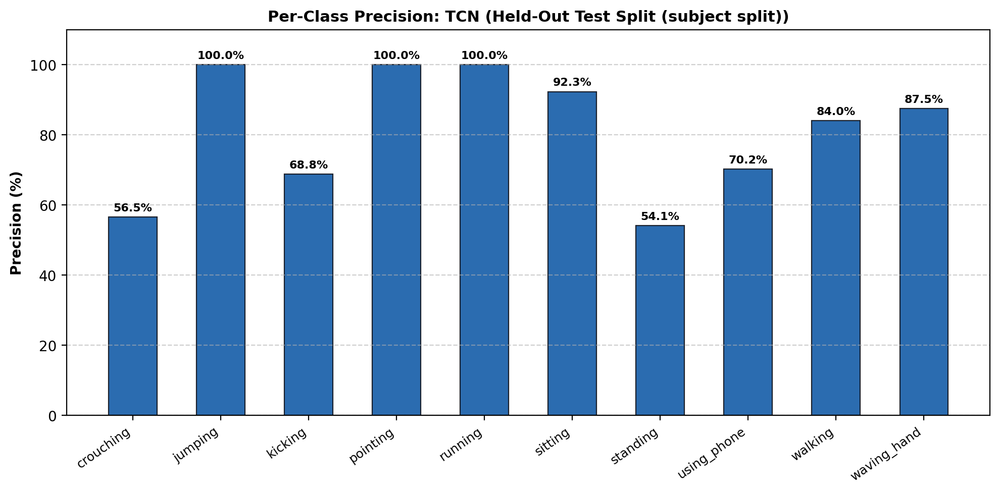

outputs/final_test/all_models/tcn_sensor_only_plots/test_recall_bars_tcn.png


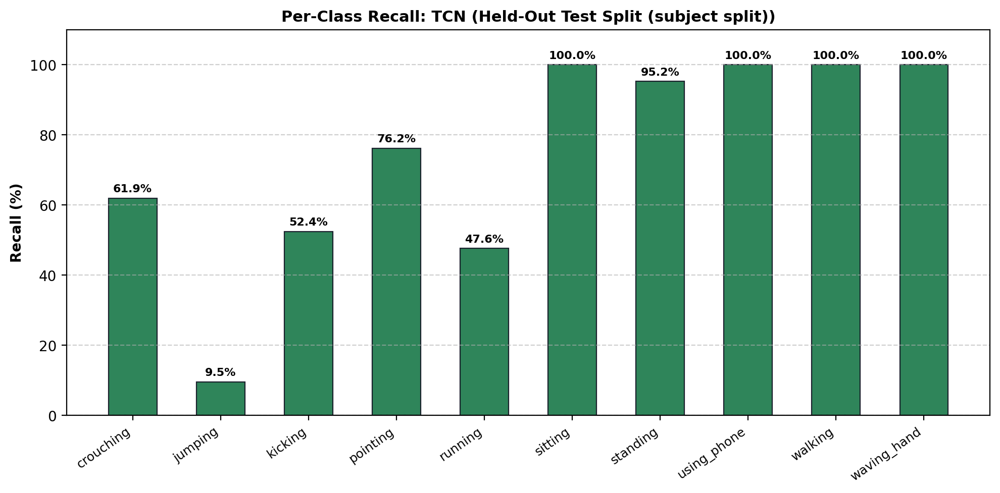

outputs/final_test/all_models/tcn_sensor_only_plots/test_f1_bars_tcn.png


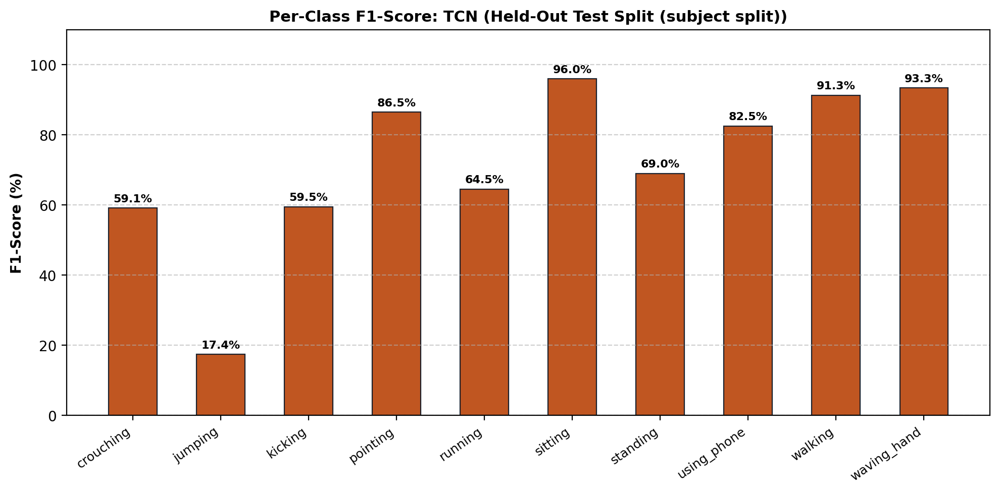

outputs/final_test/all_models/tcn_sensor_only_plots/test_roc_ovr.png


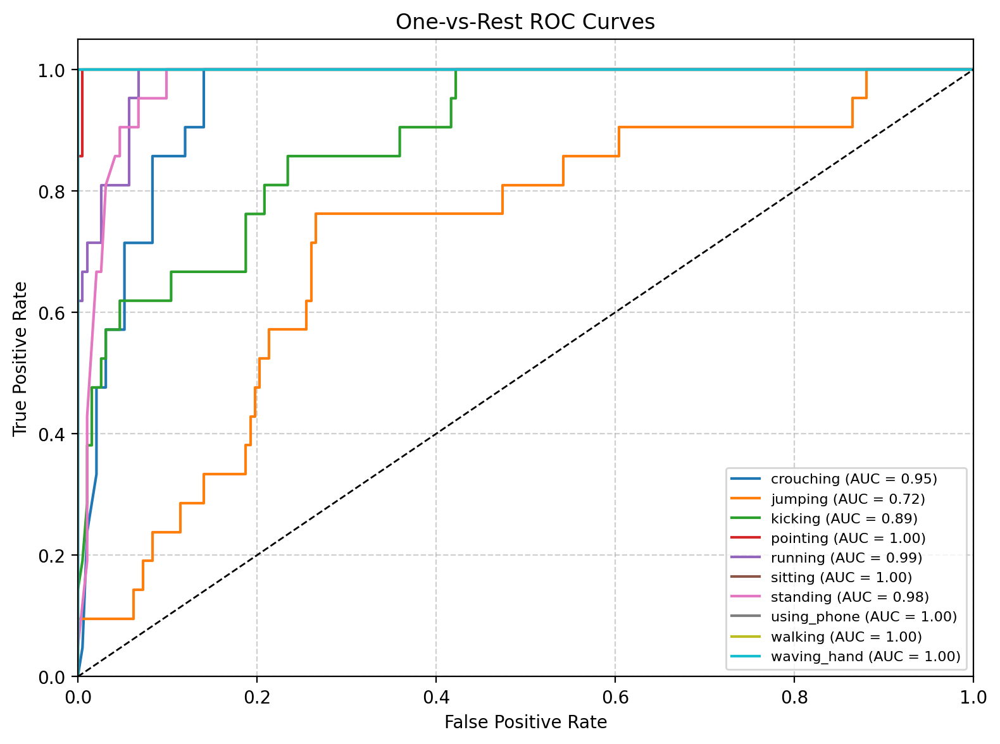

outputs/final_test/all_models/tcn_sensor_only_plots/test_pr_curves.png


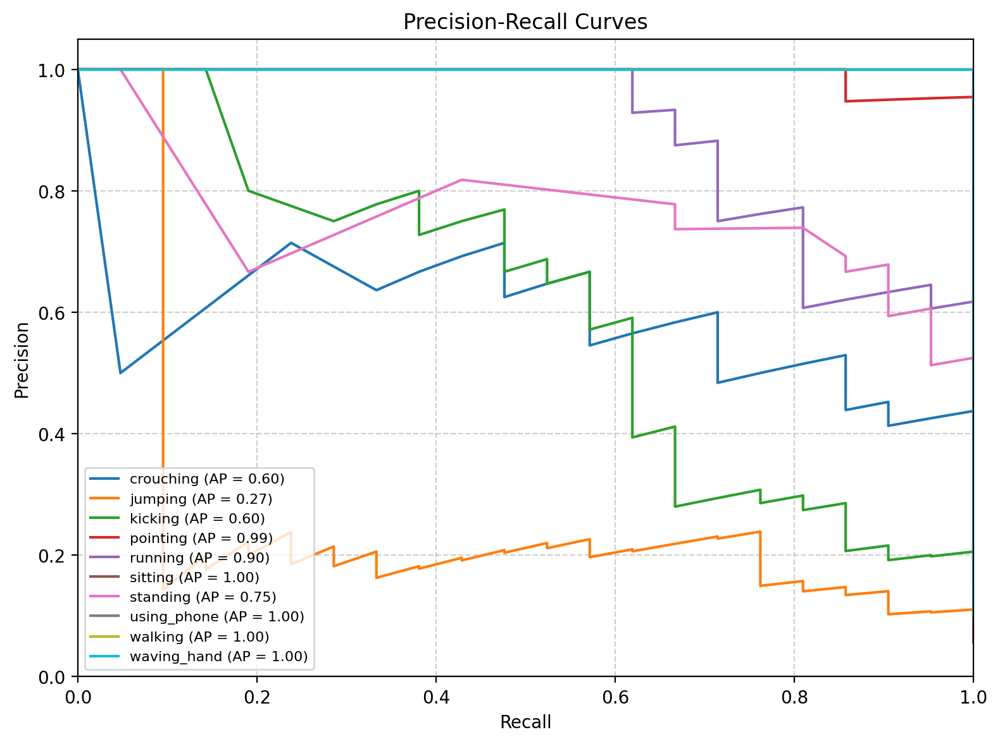

Displayed 6/6 available images.


### Gated Multimodal TCN — Held-out Test Evaluation

outputs/final_test/all_models/tcn_gated_fusion_plots/test_confusion_matrix.png


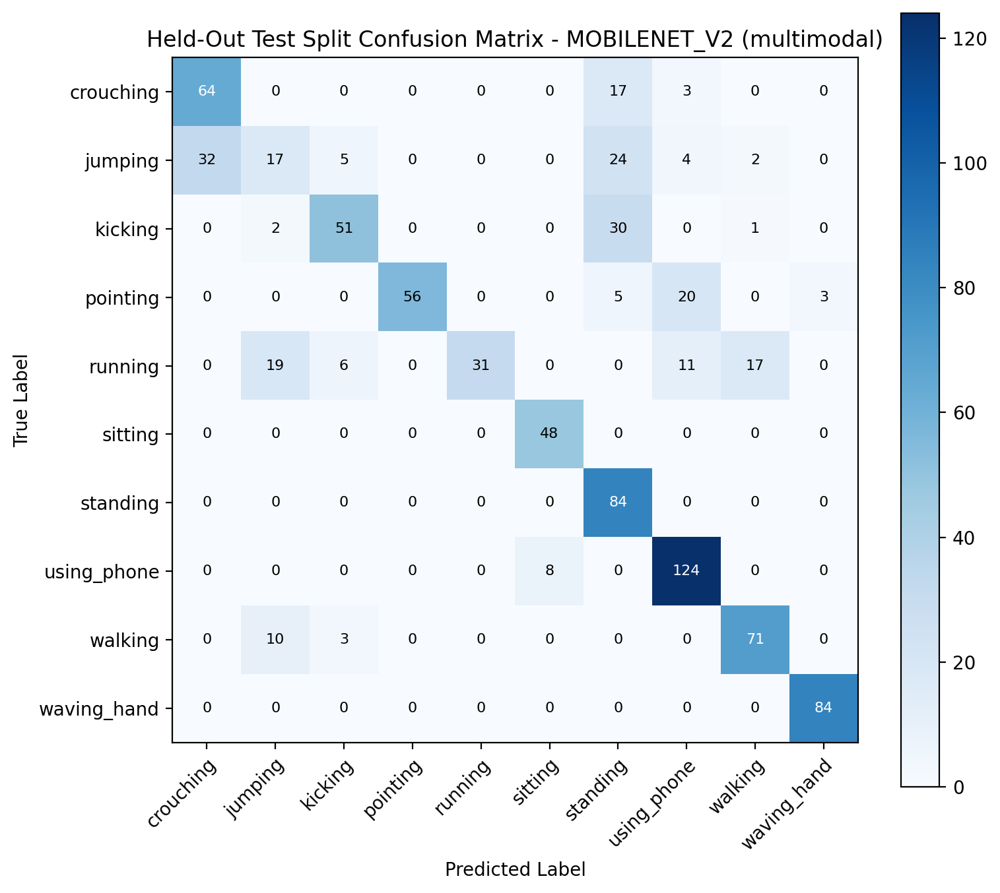

outputs/final_test/all_models/tcn_gated_fusion_plots/test_precision_bars_mobilenet_v2.png


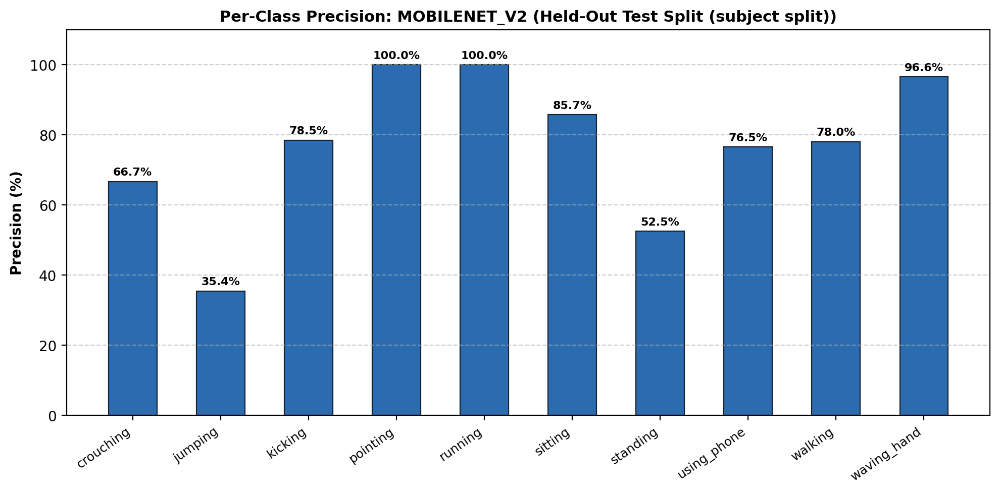

outputs/final_test/all_models/tcn_gated_fusion_plots/test_recall_bars_mobilenet_v2.png


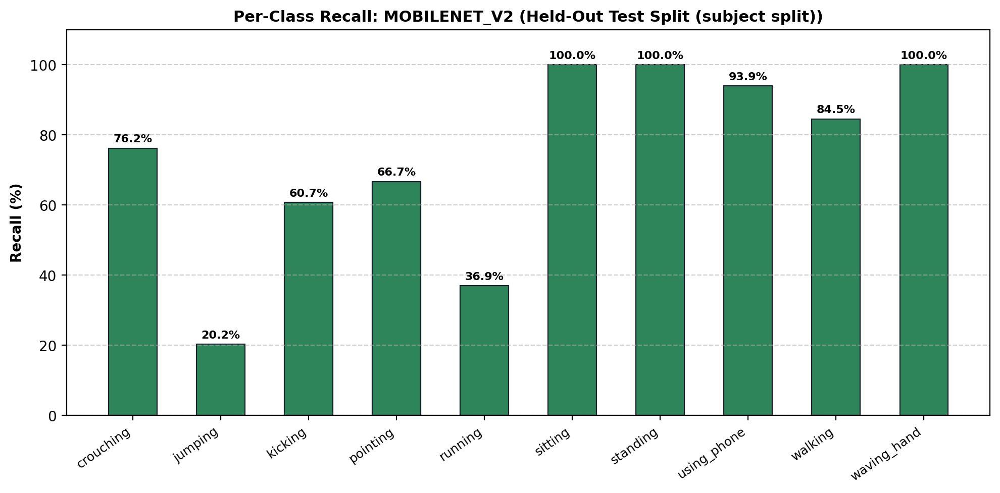

outputs/final_test/all_models/tcn_gated_fusion_plots/test_f1_bars_mobilenet_v2.png


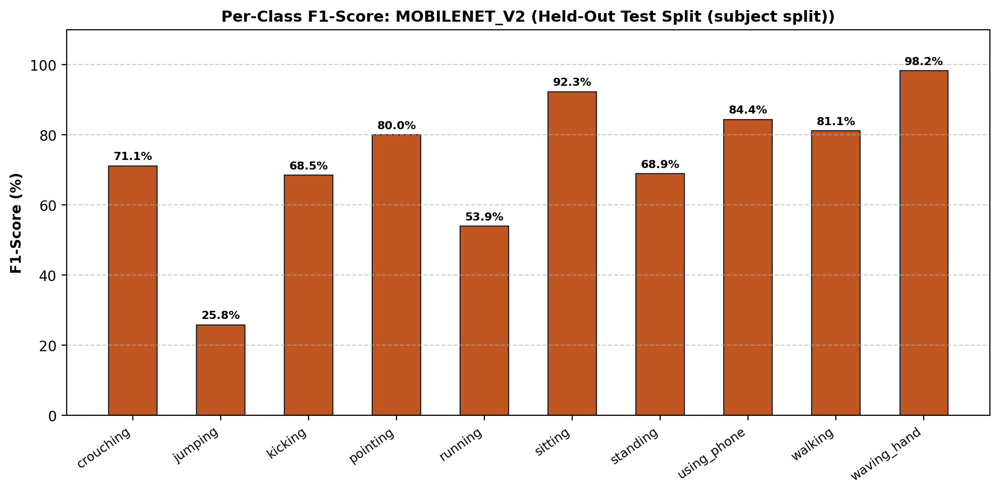

outputs/final_test/all_models/tcn_gated_fusion_plots/test_roc_ovr.png


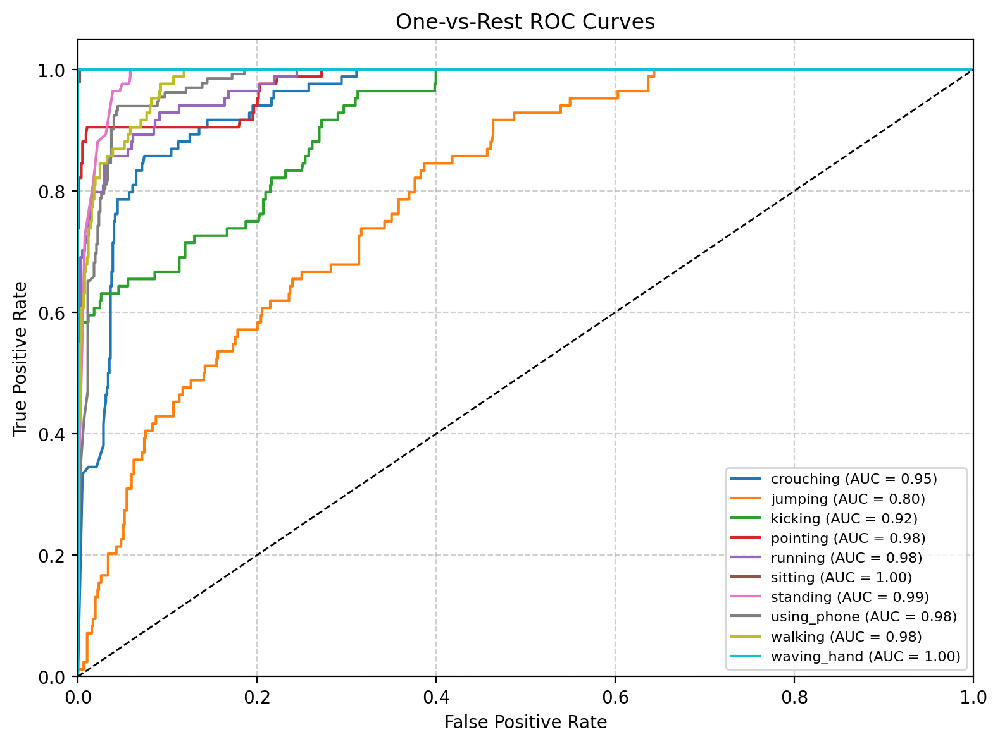

outputs/final_test/all_models/tcn_gated_fusion_plots/test_pr_curves.png


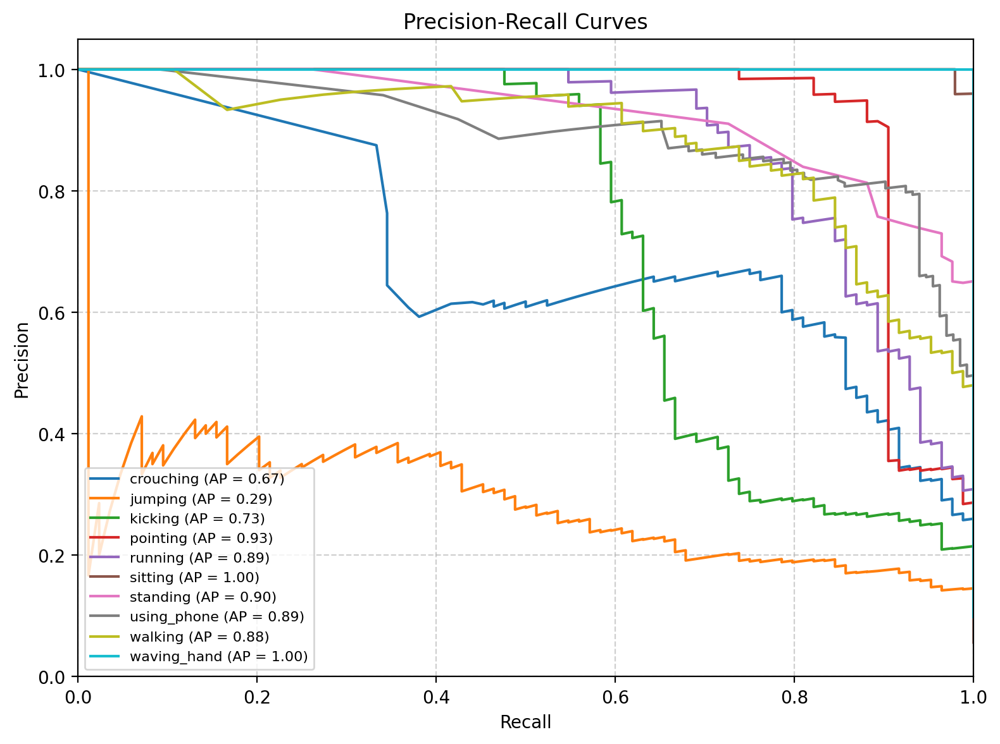

Displayed 6/6 available images.


### Primary Multimodal — Validation Diagnostics (not test)

outputs/benchmark_validation/exp1_multimodal/plots/val_confusion_matrix.png


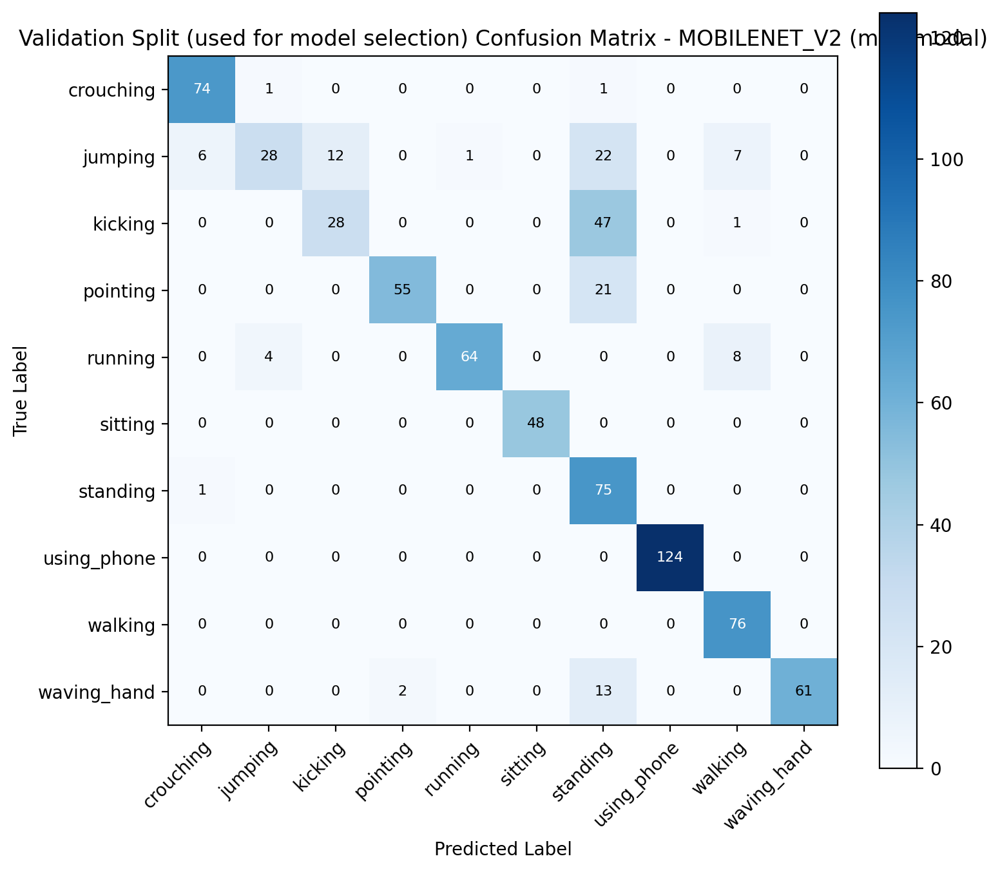

outputs/benchmark_validation/exp1_multimodal/plots/val_precision_bars_mobilenet_v2.png


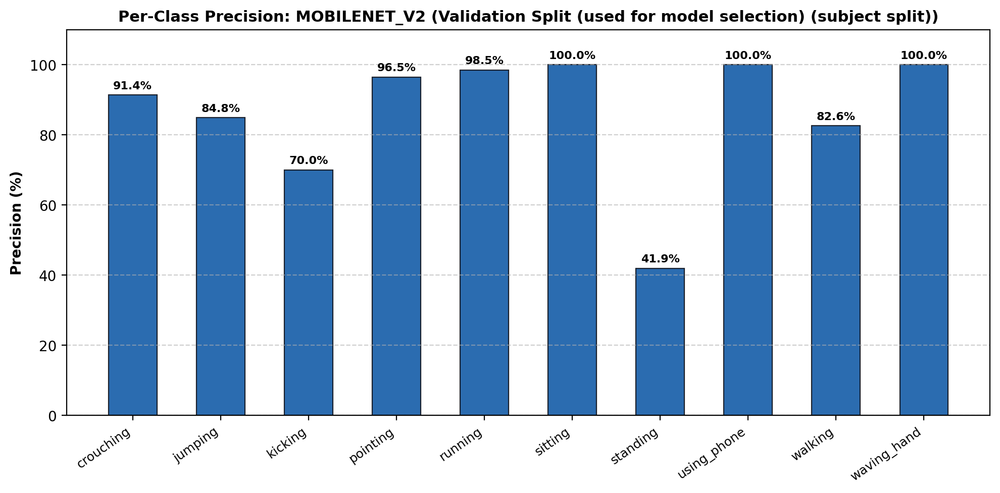

outputs/benchmark_validation/exp1_multimodal/plots/val_recall_bars_mobilenet_v2.png


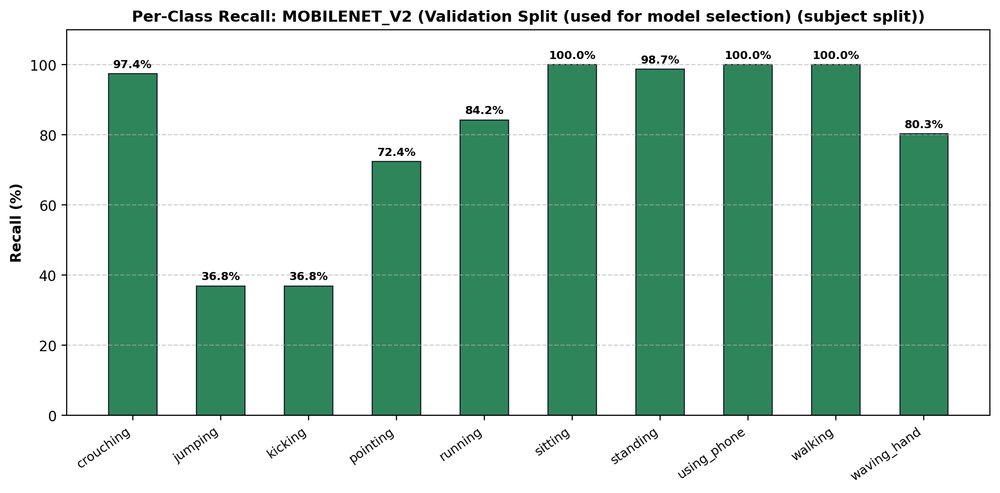

outputs/benchmark_validation/exp1_multimodal/plots/val_f1_bars_mobilenet_v2.png


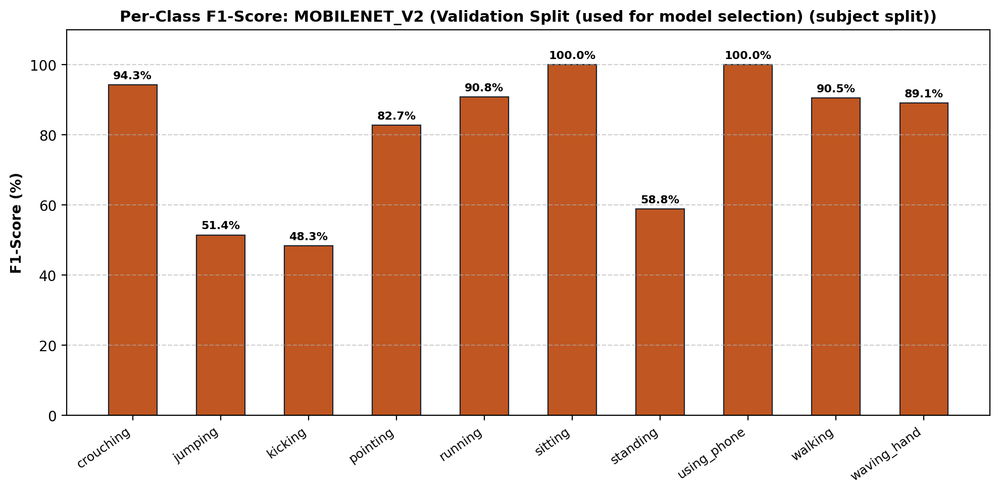

outputs/benchmark_validation/exp1_multimodal/plots/val_roc_ovr.png


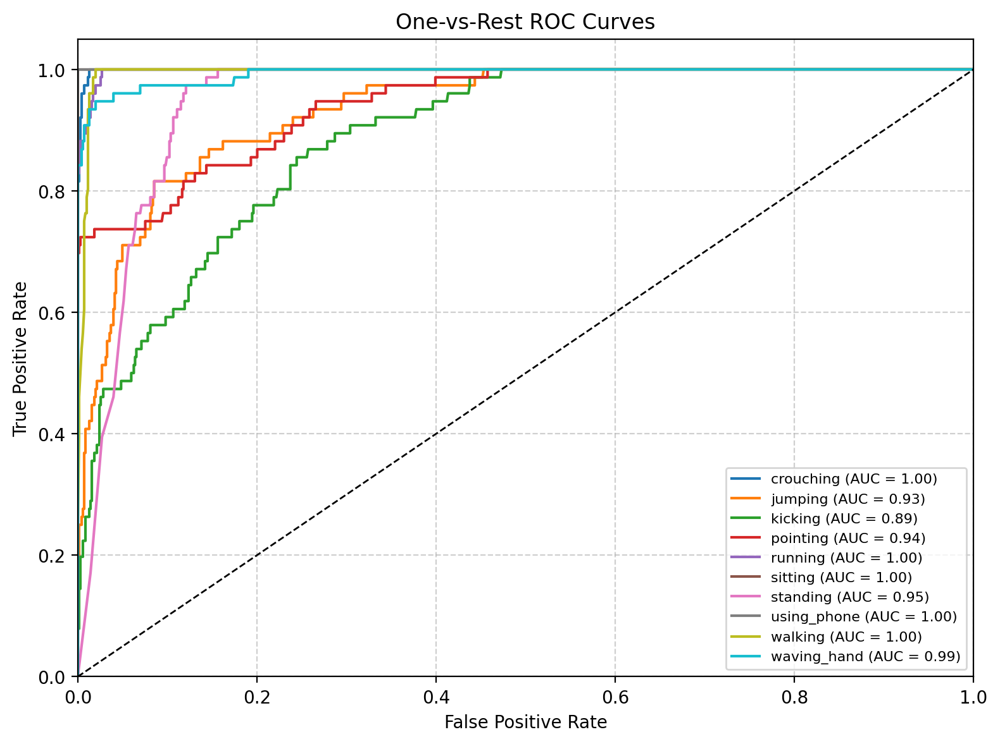

outputs/benchmark_validation/exp1_multimodal/plots/val_pr_curves.png


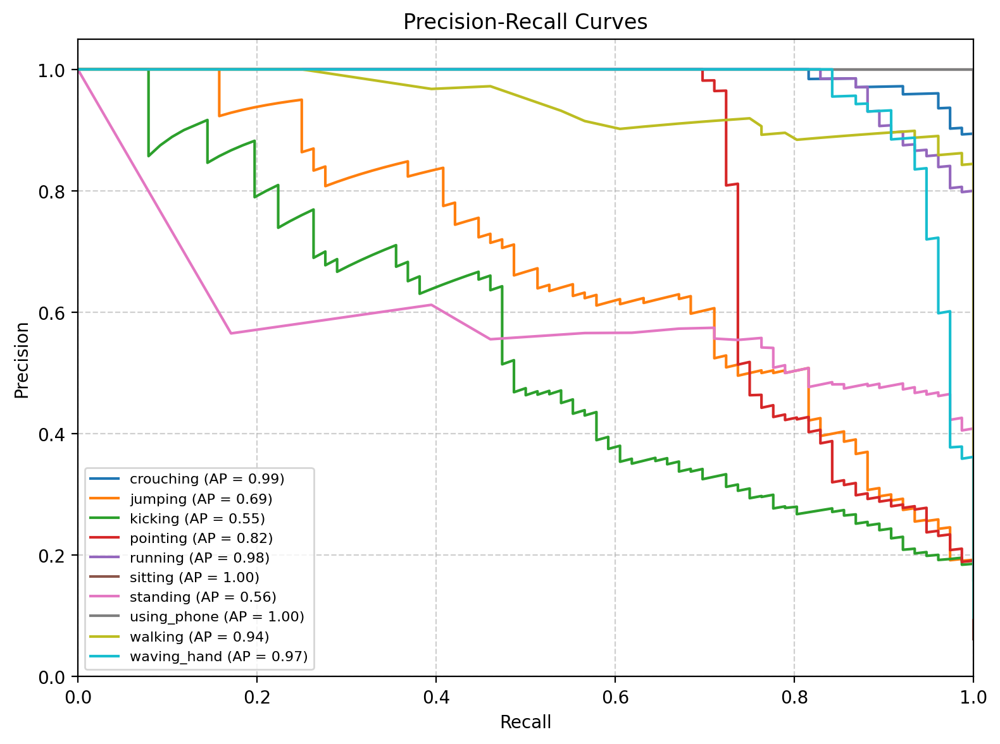

Displayed 6/6 available images.


In [10]:
# Primary multimodal held-out TEST evaluation
show_many("Primary Multimodal — Held-out Test Evaluation", [
    "outputs/exp1_multimodal/final_test_plots/test_confusion_matrix.png",
    "outputs/exp1_multimodal/final_test_plots/test_precision_bars_mobilenet_v2.png",
    "outputs/exp1_multimodal/final_test_plots/test_recall_bars_mobilenet_v2.png",
    "outputs/exp1_multimodal/final_test_plots/test_f1_bars_mobilenet_v2.png",
    "outputs/exp1_multimodal/final_test_plots/test_roc_ovr.png",
    "outputs/exp1_multimodal/final_test_plots/test_pr_curves.png",
])

# Other saved test evaluations
for model, folder in [
    ("Custom CNN", "outputs/improved_cnn/final_test_plots"),
    ("MobileNetV2", "outputs/mobilenet_v2/final_test_plots"),
    ("Sensor-only InceptionTime", "outputs/sensor_only_inception_time_v2_retrained/final_test_plots"),
    ("Sensor-only TCN", "outputs/final_test/all_models/tcn_sensor_only_plots"),
    ("Gated Multimodal TCN", "outputs/final_test/all_models/tcn_gated_fusion_plots"),
]:
    show_many(model + " — Held-out Test Evaluation", [
        f"{folder}/test_confusion_matrix.png",
        f"{folder}/test_precision_bars_" + (
            "custom_cnn.png" if model == "Custom CNN" else
            "mobilenet_v2.png" if model == "Gated Multimodal TCN" else
            "inception_time.png" if model == "Sensor-only InceptionTime" else
            "tcn.png" if model == "Sensor-only TCN" else
            "mobilenet_v2.png"
        ),
        f"{folder}/test_recall_bars_" + (
            "custom_cnn.png" if model == "Custom CNN" else
            "mobilenet_v2.png" if model == "Gated Multimodal TCN" else
            "inception_time.png" if model == "Sensor-only InceptionTime" else
            "tcn.png" if model == "Sensor-only TCN" else
            "mobilenet_v2.png"
        ),
        f"{folder}/test_f1_bars_" + (
            "custom_cnn.png" if model == "Custom CNN" else
            "mobilenet_v2.png" if model == "Gated Multimodal TCN" else
            "inception_time.png" if model == "Sensor-only InceptionTime" else
            "tcn.png" if model == "Sensor-only TCN" else
            "mobilenet_v2.png"
        ),
        f"{folder}/test_roc_ovr.png",
        f"{folder}/test_pr_curves.png",
    ])

# Separate validation diagnostics for primary model
show_many("Primary Multimodal — Validation Diagnostics (not test)", [
    "outputs/benchmark_validation/exp1_multimodal/plots/val_confusion_matrix.png",
    "outputs/benchmark_validation/exp1_multimodal/plots/val_precision_bars_mobilenet_v2.png",
    "outputs/benchmark_validation/exp1_multimodal/plots/val_recall_bars_mobilenet_v2.png",
    "outputs/benchmark_validation/exp1_multimodal/plots/val_f1_bars_mobilenet_v2.png",
    "outputs/benchmark_validation/exp1_multimodal/plots/val_roc_ovr.png",
    "outputs/benchmark_validation/exp1_multimodal/plots/val_pr_curves.png",
])

## 8. Model comparison — canonical nine-model benchmark

The benchmark below is read from the canonical tracked CSV in the repository. The rebuilt `outputs/model_comparison/rebuilt_nine_model/` folder was created in a Kaggle session and is not required here.

The nine model entries share the same held-out test membership: 852 samples per model. The test split is the custom subject-independent split, not the official MMAct competition split.

,model,best_checkpoint_epoch,completed_epochs,train_accuracy_at_checkpoint_pct,validation_accuracy_at_checkpoint_pct,test_accuracy_pct,macro_precision,macro_recall,macro_f1,roc_auc_ovr,average_precision_macro,test_samples,same_test_membership,history_file,evaluation_file
0,Primary Multimodal,49,50,98.208169,81.153846,76.760563,0.784329,0.765152,0.754462,0.966135,0.858999,852,True,outputs/exp1_multimodal/history.json,outputs/exp1_multimodal/test_evaluation_v2.json
1,Additional Multimodal Fusion,30,50,96.785244,80.384615,75.469484,0.777025,0.753788,0.746400,0.966230,0.849982,852,True,outputs/multimodal_fusion/history.json,outputs/final_test/rebuild_staging/multimodal_...
2,Sensor-only TCN,42,50,96.706192,77.435897,74.647887,0.813346,0.742857,0.719047,0.952381,0.809367,852,True,outputs/tcn_sensor_only/history.json,outputs/final_test/rebuild_staging/tcn_sensor_...
3,Gated Multimodal TCN,31,50,98.418972,77.692308,73.943662,0.769876,0.739177,0.724140,0.958214,0.826765,852,True,outputs/tcn_gated_fusion/history.json,outputs/final_test/rebuild_staging/tcn_gated_f...
4,Sensor-only InceptionTime,42,50,84.426877,76.923077,68.544601,0.706957,0.680952,0.656283,0.931106,0.774191,852,True,outputs/sensor_only_inception_time_v2_retraine...,outputs/sensor_only_inception_time_v2_retraine...
5,Retrained MobileNetV2,32,44,55.962095,36.538462,42.488263,0.466550,0.455168,0.431693,0.844296,0.473153,852,True,outputs/mobilenet_v2_staged_v2_retrained/histo...,outputs/mobilenet_v2_staged_v2_retrained/test_...
6,Original MobileNetV2,41,50,49.986825,35.256410,42.136150,0.447326,0.458983,0.415329,0.860878,0.498242,852,True,outputs/mobilenet_v2/history.json,outputs/final_test/rebuild_staging/mobilenet_v...
7,Original Custom CNN,47,50,15.968379,14.743590,15.375587,0.154051,0.172673,0.113918,0.616007,0.179127,852,True,outputs/improved_cnn/history.json,outputs/final_test/rebuild_staging/improved_cn...
8,Retrained Custom CNN V2,17,30,16.056857,13.461538,13.262911,0.130708,0.144913,0.093973,0.609066,0.178565,852,True,outputs/improved_cnn_v2_retrained_v2/history.json,outputs/final_test/rebuild_staging/improved_cn...


Best model: Primary Multimodal
Test Accuracy: 76.7606%
Macro-F1: 0.7544618
ROC-AUC OvR: 0.9661350
Test samples per model: [np.int64(852)]


### Nine-model Canonical Benchmark Graphs

outputs/final_test/all_models_rebuilt/training_vs_testing_accuracy.png


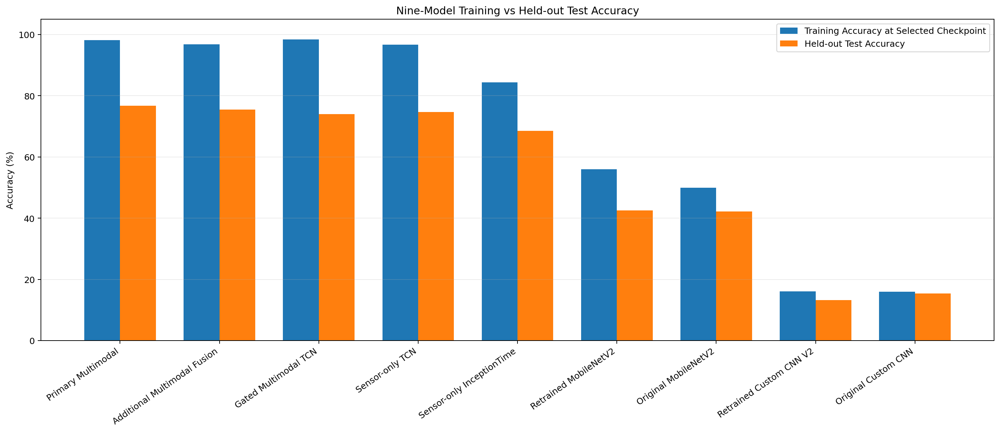

outputs/final_test/all_models_rebuilt/training_accuracy_comparison.png


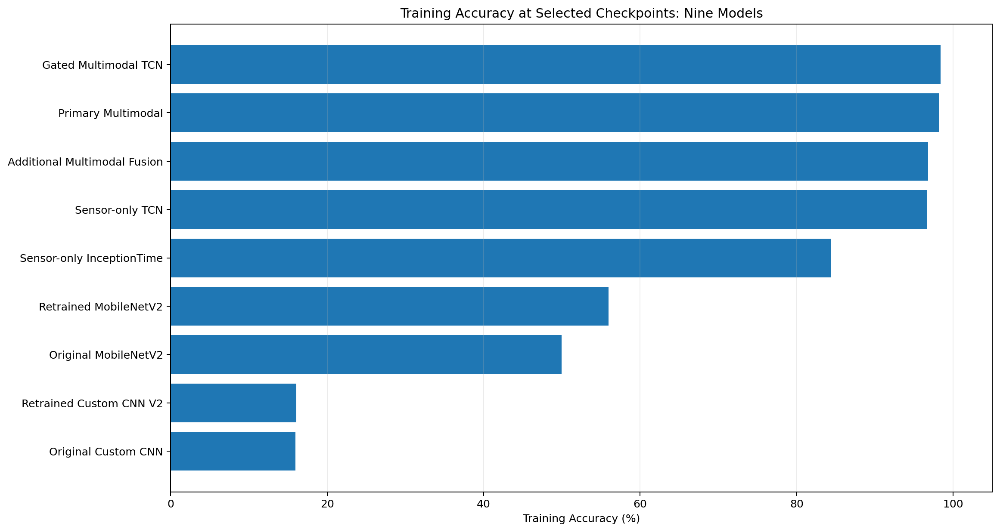

outputs/final_test/all_models_rebuilt/testing_accuracy_comparison.png


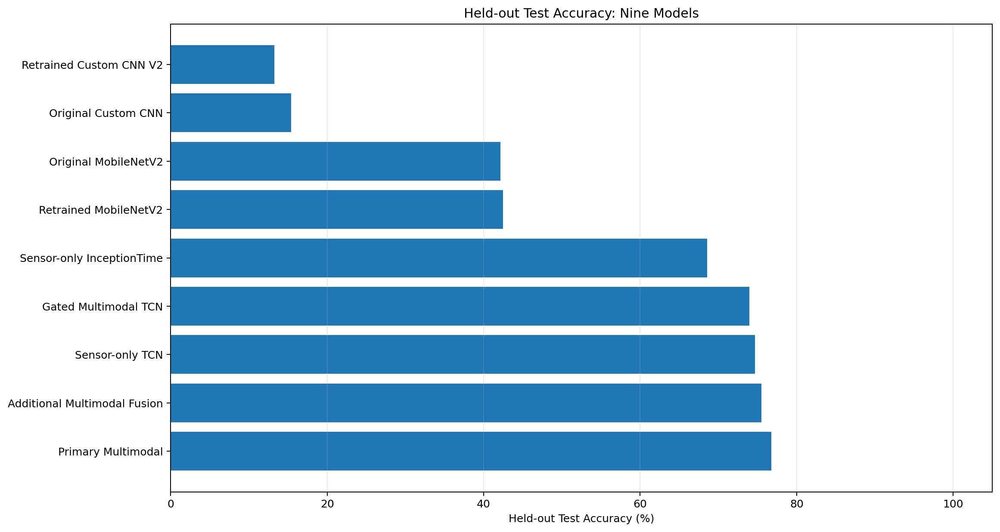

outputs/final_test/all_models_rebuilt/macro_f1_comparison.png


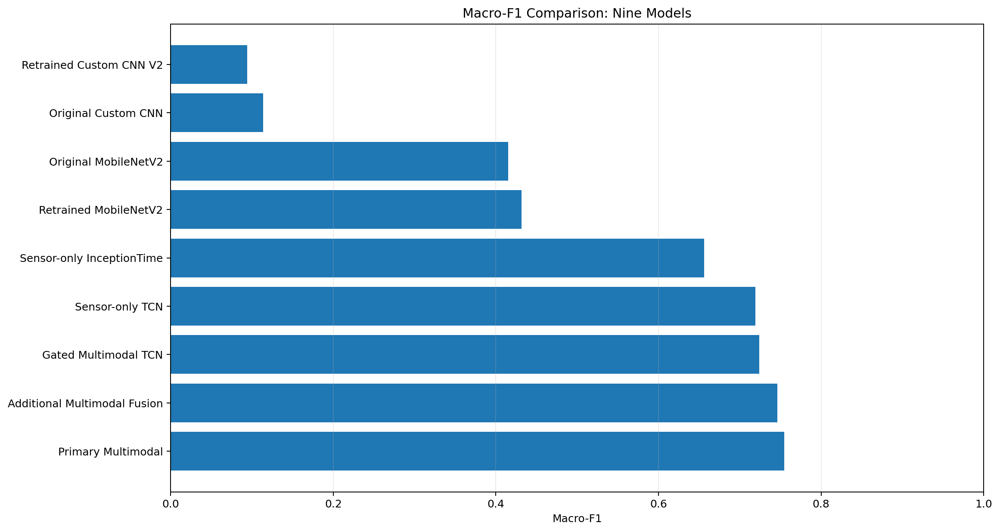

Displayed 4/4 available images.


### CNN vs MobileNetV2

outputs/final_test/all_models/cnn_vs_mobilenet_v2_comparison.png


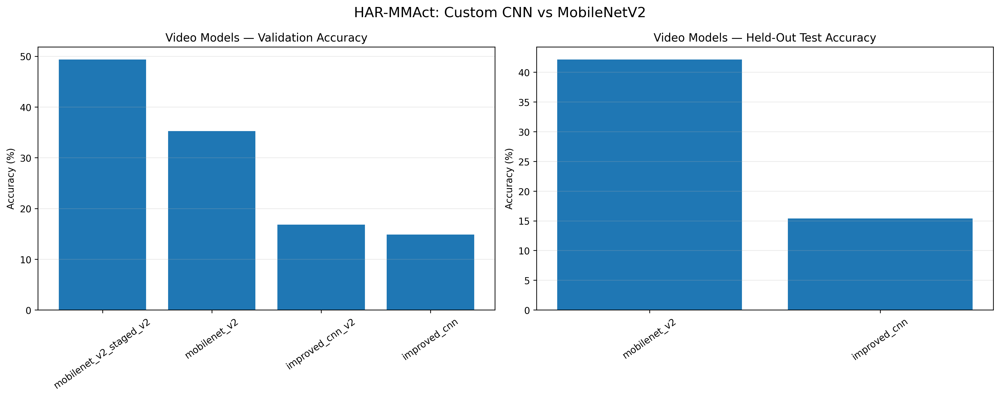

### Video-only vs Sensor-only vs Multimodal

outputs/final_test/all_models/modality_model_test_comparison.png


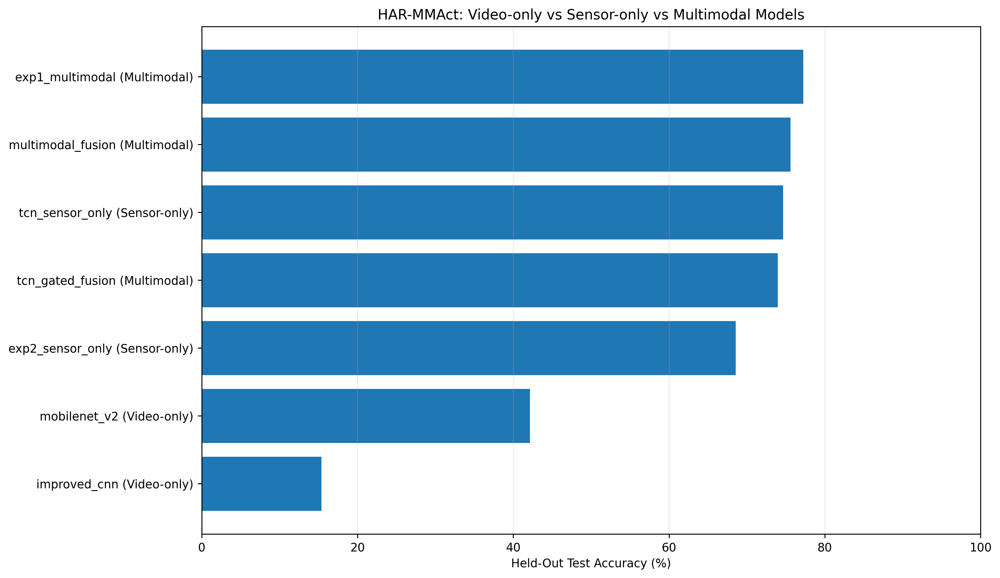

True

In [11]:
benchmark_path = OUTPUTS / "final_test/all_models_rebuilt/nine_model_comparison.csv"
if not benchmark_path.exists():
    raise FileNotFoundError(f"Canonical benchmark not found: {benchmark_path}")

benchmark = pd.read_csv(benchmark_path)
assert len(benchmark) == 9
assert (benchmark["test_samples"] == 852).all()
assert benchmark["same_test_membership"].astype(str).str.lower().eq("true").all()

benchmark = benchmark.sort_values("test_accuracy_pct", ascending=False).reset_index(drop=True)
display(benchmark)

best = benchmark.iloc[0]
print("Best model:", best["model"])
print(f"Test Accuracy: {best['test_accuracy_pct']:.4f}%")
print(f"Macro-F1: {best['macro_f1']:.7f}")
print(f"ROC-AUC OvR: {best['roc_auc_ovr']:.7f}")
print("Test samples per model:", sorted(benchmark["test_samples"].unique()))

# Canonical comparison visualizations tracked in GitHub
show_many("Nine-model Canonical Benchmark Graphs", [
    "outputs/final_test/all_models_rebuilt/training_vs_testing_accuracy.png",
    "outputs/final_test/all_models_rebuilt/training_accuracy_comparison.png",
    "outputs/final_test/all_models_rebuilt/testing_accuracy_comparison.png",
    "outputs/final_test/all_models_rebuilt/macro_f1_comparison.png",
])

# CNN versus MobileNetV2 and modality comparisons
show_image("outputs/final_test/all_models/cnn_vs_mobilenet_v2_comparison.png",
           "CNN vs MobileNetV2")
show_image("outputs/final_test/all_models/modality_model_test_comparison.png",
           "Video-only vs Sensor-only vs Multimodal")

## 9. Conclusion and limitations

### Verified best model: Primary Multimodal

- Test accuracy: **76.7606%**
- Macro-F1: **0.7544618**
- Macro precision: **0.7843291**
- Macro recall: **0.7651515**
- ROC-AUC (OvR): **0.9661350**
- Macro average precision: **0.8589989**
- Selected checkpoint: **epoch 49**
- Completed epochs: **50**
- Held-out test samples: **852**

### Limitations

1. This is a custom subject-independent evaluation split (train 1–14, validation 15–17, test 18–20), not the official MMAct competition split.
2. The canonical benchmark confirms 9 models with common test membership. Separate exploratory experiments should not be treated as members of that benchmark unless their split and test membership are documented.
3. The tracked benchmark documents completed runs of 30, 44, or 50 epochs depending on model. Do not claim verified 100- or 150-epoch results.
4. The project README and `docs/LABEL_MAPPING.md` document the ten target activity classes and mapping.
5. Training/validation curves are not per-epoch held-out test evaluations.
6. This notebook displays saved repository artifacts. It does not retrain models or regenerate benchmark metrics.

For detailed method, dataset audit, labels, and implementation, refer to `README.md`, `docs/DATASET_AUDIT.md`, `docs/LABEL_MAPPING.md`, and `docs/FINAL_PROJECT_REPORT.md`.

In [12]:
print("PRESENTATION NOTEBOOK COMPLETE")
print("Repository:", REPO)
print("Canonical benchmark rows:", len(benchmark))
print("Shared test membership:", benchmark["same_test_membership"].astype(str).str.lower().all())
print("Test samples per model:", sorted(benchmark["test_samples"].unique()))
print("Best model:", best["model"])
print(f"Best test accuracy: {best['test_accuracy_pct']:.4f}%")
print("No model training was run by this notebook.")

PRESENTATION NOTEBOOK COMPLETE
Repository: /kaggle/working/HAR-MMAct
Canonical benchmark rows: 9
Shared test membership: True
Test samples per model: [np.int64(852)]
Best model: Primary Multimodal
Best test accuracy: 76.7606%
No model training was run by this notebook.
